In [ ]:
#2026/01/16 unaltered from intermediate version of G:\Shared drives\SlumpingOAB\metrology_data\analysis\20250909_RP2\Mandrels_PSDs_v1VC.ipynb
# this can be adjusted to a good example for iterative outliers removal.

In [1]:
#2026/01/14 plot for CXM mandrels for review of RP2 (figure 39),
# reproducing slide 5 of 
# https://docs.google.com/presentation/d/1N2rzSFVcruBRAXfRWReIV-wJHEmHJsi4B3tX9u6LFPw/edit?slide=id.g37ad9f3db50_0_0#slide=id.g37ad9f3db50_0_0
# with same formatting as PSDs of slumped glass PSD (figure 40)

#format of figure 40 from 
# G:\Shared drives\SlumpingOAB\metrology_data\analysis\SS_slumping_psds_23102025-20251023T145725Z-1-001\SS_slumping_psds_23102025\redo_psd_spie_vs.ipynb

In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
import os, pathlib, numpy as np, matplotlib.pyplot as plt
#from pySurf.scripts.MIRO_analysis_functions import plot_psd
#from pySurf.MIRO_analysis_functions import plot_psd
import numpy as np
import matplotlib.pyplot as plt
from pySurf.readers.instrumentReader import matrixdat_reader
from pySurf.data2D_class import Data2D
from pySurf.readers.format_reader import read_nid
#from pySurf.scripts.dlist import Dlist,load_dlist
from pySurf.scripts.dlist import Dlist,load_dlist
#from pySurf.MIRO_analysis_functions import *
#from pySurf.readers.nid_reader import read_nid
from pyProfile.profile import save_profile,crop_profile
from scipy.stats import binned_statistic
from pySurf.readers.instrumentReader import matrixdat_reader,matrixZygo_reader, matrix_reader, matrix4D_reader


from pySurf.data2D_class import Data2D
from pySurf.data2D import plot_data
from dataIO.fn_add_subfix import fn_add_subfix
from pyProfile.psd import plot_psd, psd_units

import os
import numpy as np
from matplotlib import pyplot as plt
from scipy import ndimage

from pySurf.data2D_class import Data2D
from pySurf.data2D import plot_data
from dataIO.fn_add_subfix import fn_add_subfix
from pySurf.fit_cylinder import fit_cylinder, fit_cone
from pySurf.points import resample_grid, subtract_points, plot_points, points_autoresample



from plotting.backends import maximize
from dataIO.span import span

import inspect
import warnings
import pickle
warnings.filterwarnings('ignore')

In [4]:
from pyProfile.profile_class import Profile

In [5]:
%qtconsole

In [33]:
from pyProfile.profile_class import read_chr

fk20 =  r'..\..\Chrocodile\20250528_firstAcquisition\mould k20 n1.txt' 

p = Profile(*read_chr(fk20),units =['um','nm'], name='croc_k20n1',scale=(1000,1000))

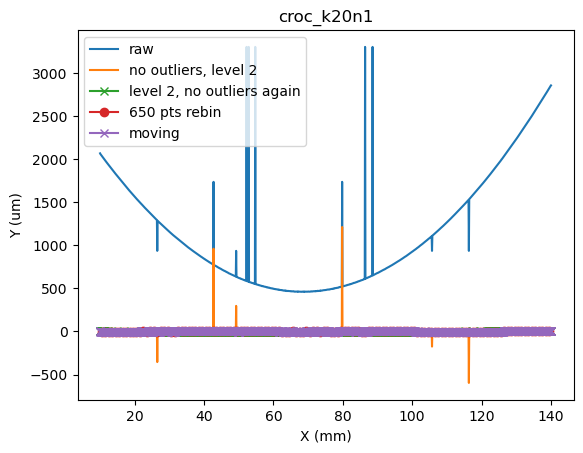

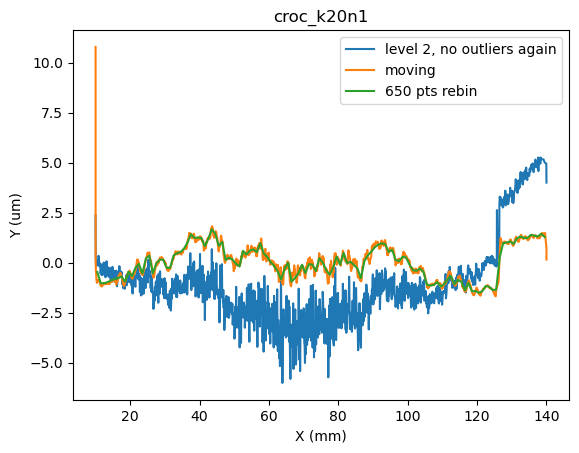

In [66]:

#p.movingaverage(151).plot()
# p.level(2).plot()

p.plot(label='raw')
p1 = p.remove_outliers(itmax=2,correct=True).level(2)    # clearly outliers smaller than sag are not removed, need further leveling
#can probably be made in one step by passing leveling function to remove_outliers.
p1.plot(label = 'no outliers, level 2')
p1.level(2).remove_outliers(itmax=2,correct=True).plot(label = 'level 2, no outliers again',marker='x')
p.level(2).remove_outliers(itmax=2,correct=True).rebin(bins=130).level(2).plot(label = '650 pts rebin',marker='o')
p.level(2).remove_outliers(itmax=2,correct=True).movingaverage(7).level(2).plot(label = 'moving',marker='x')
plt.legend()

plt.figure()
plt.title('with final leveling')
p1.level(2).remove_outliers(itmax=2,correct=True).plot(label = 'level 2, no outliers again')
p.level(2).remove_outliers(itmax=2,correct=True).movingaverage(7).level(2).plot(label = 'moving')
p.level(2).remove_outliers(itmax=2,correct=True).rebin(bins=130).level(2).plot(label = '650 pts rebin')
plt.legend()

p_final = p.level(2).remove_outliers(itmax=2,correct=True).rebin(bins=130).level(2)

first argument is string, use it as filename


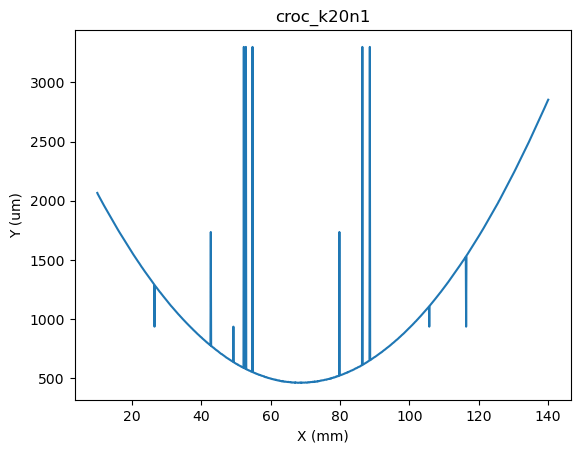

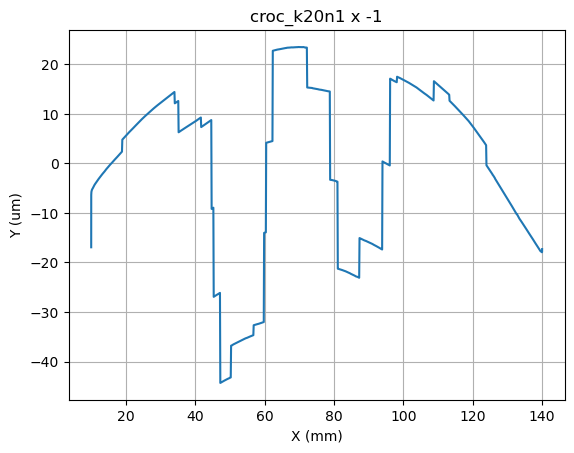

In [52]:
#K20 Zerdour

import numpy as np
import matplotlib.pyplot as plt

import numpy as np

def comma_to_float(s):
    return float(s.replace(',', '.'))

# alternatively, create object directly with file name:
#  fk20 =  'croc_k20n1.txt' #old
p = Profile(fk20,units =['mm','um'], name='croc_k20n1',
         skip_header=1,
         usecols=(2, 3),
         converters={2: comma_to_float, 3: comma_to_float},
         encoding='latin1')

p.plot(); plt.show()
plt.grid(True)

pk20=-p#.movingaverage(15)
p2_k20 = pk20.level(2) #this is simply removing a second order Legendre
p2_k20=p2_k20.movingaverage(151)
p2_k20.plot(); plt.show()



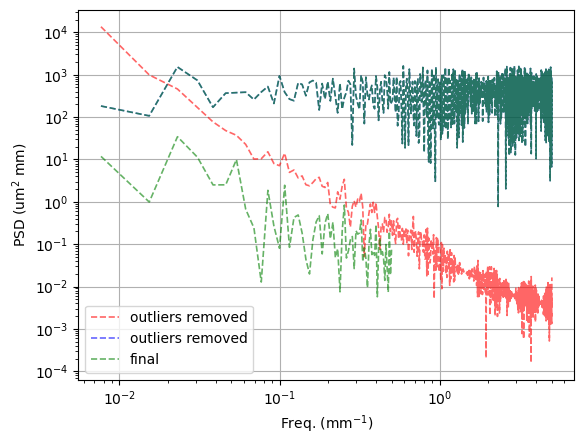

In [58]:
pp=p.level(2).remove_outliers(itmax=2,correct=True).movingaverage(7)

#p2_k20.psd().plot(label='croc k20') #this is a psd object

pp.psd().plot(ls='--', lw=1.2,color='r',alpha=0.6, label  = "outliers removed")
p1.psd().plot(ls='--', lw=1.2,color='b',alpha=0.6, label = "outliers removed")
p1.level(2).psd().plot(ls='--', lw=1.2,color='g',alpha=0.6)
p_final.psd().plot(ls='--', lw=1.2,color='g',alpha=0.6, label = "final")

In [29]:
#INOX/LMSS02

import numpy as np
import matplotlib.pyplot as plt

import numpy as np

def comma_to_float(s):
    return float(s.replace(',', '.'))

def read_chrocodile(fn):
    """ Read data from a crocodile file.
    
    Accetta una stringa, sostituisce ',' con '.' e converte in float
    """

    data = np.genfromtxt(
        'mould_inoxn1.txt',
        delimiter='\t',
        skip_header=1,
        usecols=(2, 3),
        converters={2: comma_to_float, 3: comma_to_float},
        dtype=float,
        encoding='latin1',unpack=True
    )

    return data

#x,z = read_chrocodile('/home/varun/PSD_AFM/mould_inoxn1.txt')

# load data in a profile object 
from pyProfile.profile_class import Profile

#p = Profile(x,z, units =['mm','um'], name='mould_inoxn1')

# alternatively, create object directly with file name:
#
p = Profile('mould_inoxn1.txt',units =['mm','um'], name='Mould_Inox_n1',
         skip_header=1,
         usecols=(2, 3),
         converters={2: comma_to_float, 3: comma_to_float},
         encoding='latin1')

p.plot(); plt.show()
plt.grid(True)

pinox=-p#.movingaverage(15)
p2_inox = pinox.level(2).movingaverage(151) #this is simply removing a second order Legendre
#p2_inox=p2_inox.movingaverge(301)
p2_inox.plot(); plt.show()

p2_inox.psd().plot(label='LMSS02'); plt.show() #this is a psd object

first argument is string, use it as filename


FileNotFoundError: mould_inoxn1.txt not found.

In [30]:
#INOX/LMSS01

import numpy as np
import matplotlib.pyplot as plt

import numpy as np

def comma_to_float(s):
    return float(s.replace(',', '.'))

def read_chrocodile(fn):
    """ Read data from a crocodile file.
    
    Accetta una stringa, sostituisce ',' con '.' e converte in float
    """

    data = np.genfromtxt(
        'mould_inox_n2.txt',
        delimiter='\t',
        skip_header=1,
        usecols=(2, 3),
        converters={2: comma_to_float, 3: comma_to_float},
        dtype=float,
        encoding='latin1',unpack=True
    )

    return data

x,z = read_chrocodile('/home/varun/PSD_AFM/mould_inoxn1.txt')

# load data in a profile object 
from pyProfile.profile_class import Profile

#p = Profile(x,z, units =['mm','um'], name='mould_inoxn1')

# alternatively, create object directly with file name:
#
p = Profile('mould_inox_n2.txt',units =['mm','um'], name='Mould_Inox_n2',
         skip_header=1,
         usecols=(2, 3),
         converters={2: comma_to_float, 3: comma_to_float},
         encoding='latin1')

p.plot(); plt.show()
plt.grid(True)

pinox=-p#.movingaverage(15)
p2_lmss01 = pinox.level(2).movingaverage(151) #this is simply removing a second order Legendre
#p2_inox=p2_inox.movingaverge(301)
p2_lmss01.plot(); plt.show()

p2_lmss01.psd().plot(label='LMSS01'); plt.show() #this is a psd object

FileNotFoundError: mould_inox_n2.txt not found.

In [ ]:
#AFM+MFT codes

<Figure size 640x480 with 0 Axes>

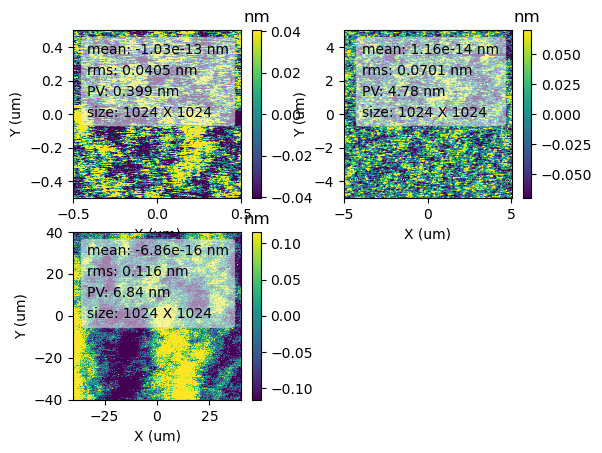

<Figure size 640x480 with 0 Axes>

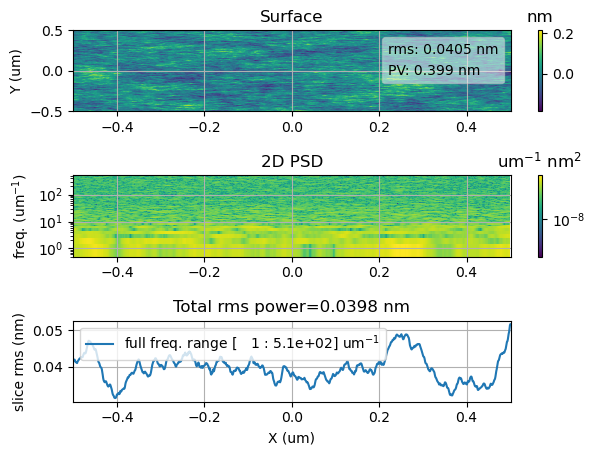

<Figure size 640x480 with 0 Axes>

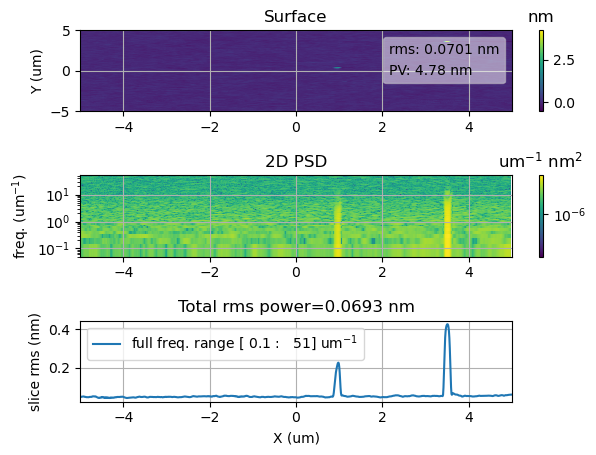

<Figure size 640x480 with 0 Axes>

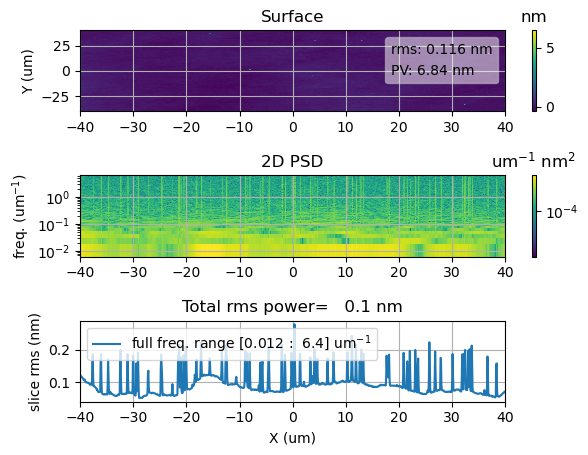

<Figure size 640x480 with 0 Axes>

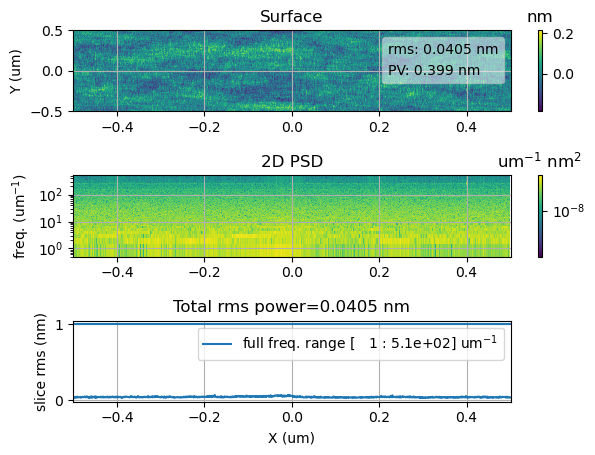

<Figure size 640x480 with 0 Axes>

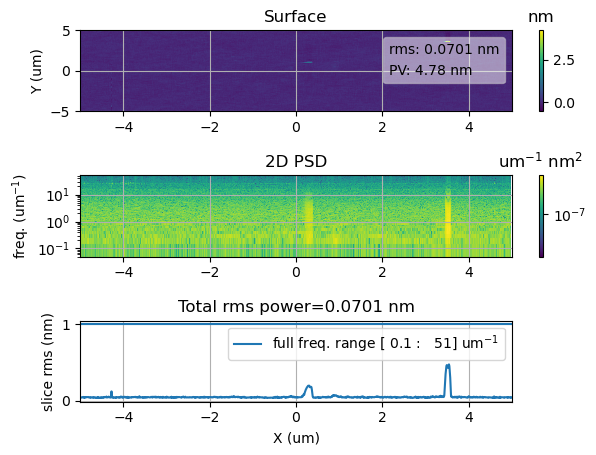

<Figure size 640x480 with 0 Axes>

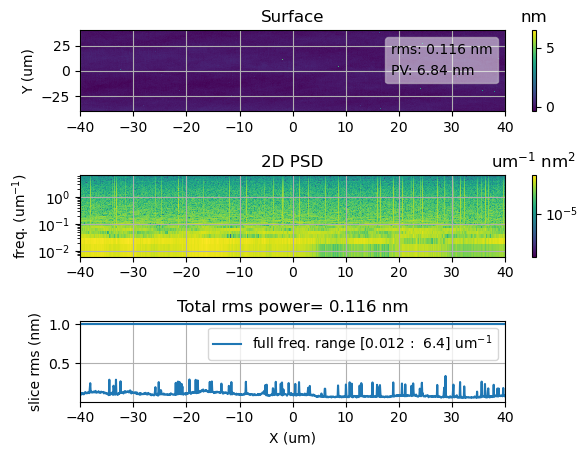

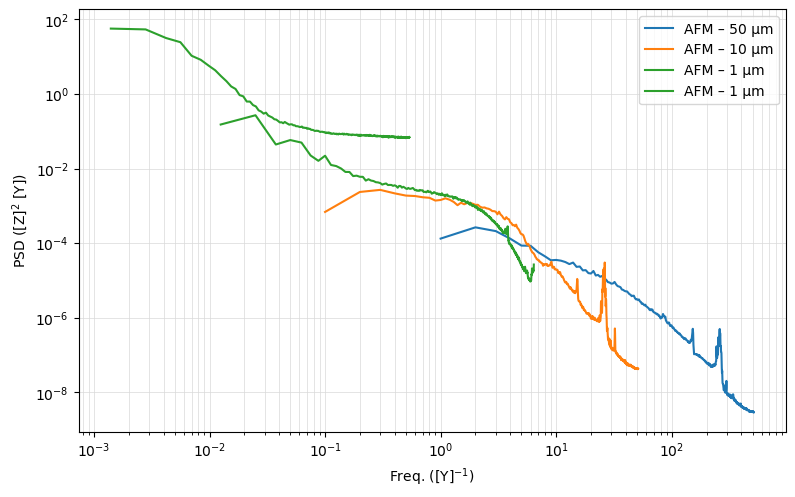

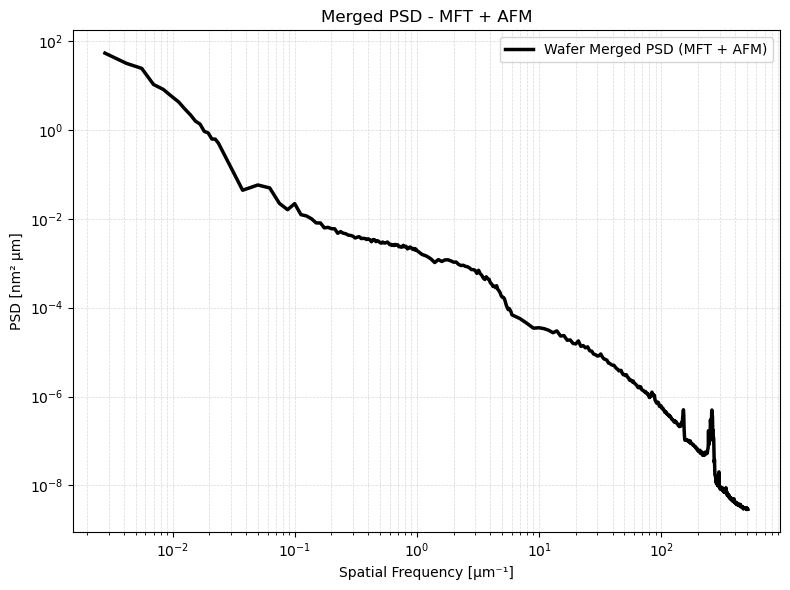

In [ ]:
#wafer AFM+MFT

#######################################################
#######################################################

#loading data
datafolder = r'/home/varun/PSD_AFM/wafer_afm/'
df = ['Image01788.nid',
      'Image01789.nid',
      'Image01790.nid']
files = [os.path.join(datafolder, f) for f in df]

#files = [os.path.join(datafolder, f) for f in df]
#outdir = r'results'  #os.path.join(datafolder,'results')
#outfolder = outdir 

labels = ['AFM - 1 um', 'AFM - 10 um', 'AFM - 50 um']

#psds = dopsd(files, labels, outfolder)
from pySurf.readers import nid_reader
data  = [read_nid(f) for f in files]
#dl = Dlist(data,units=['um','um','nm'],scale=[1e6,1e6,1e9],center = (0,0))
datalist = Dlist([Data2D(*d,units=['um','um','nm'],scale=[1e6,1e6,1e9],center = (0,0)) for d in data])  #TODO: allow reader

datalist = datalist.level(2,axis=1)
datalist.plot(type = 'grid')  #TOOD: allow figure output 
plt.show()  
afm_datalist = [(d, d.psd(analysis=True).avgpsd()) for d in datalist]


#################################################
#################################################

#plots of afm data

import os, pathlib, numpy as np, matplotlib.pyplot as plt
from pySurf.MIRO_analysis_functions import plot_psd

def psd_to_xy(psd): 
    for fx, fy in [('f','P'), ('x','y'), ('fx','py'), ('fx','P')]:
        if hasattr(psd, fx) and hasattr(psd, fy):
            return getattr(psd, fx), getattr(psd, fy)
    arr = psd.data if hasattr(psd, 'data') else psd
    return (arr[0], arr[1]) if arr.shape[0]==2 else (arr[:,0], arr[:,1])                            

#psd_list = [d.psd(axis=1, analysis=True, rmsthr=1).avgpsd()
#            for d in datalist]

#colors = ['tab:blue', 'tab:orange', 'tab:green']   # 1 µm, 10 µm, 50 µm
#labels = ['AFM – 50 µm', 'AFM – 10 µm', 'AFM – 1 µm']

#plt.figure(figsize=(8,5))
#for psd, c, lab in zip(psd_list, colors, labels):
#    f, P = psd_to_xy(psd)
    #print(f); print(P)
#    plot_psd(f, P, label=lab, color=c)           

#plt.xlabel('Frequenza spaziale [µm⁻¹]')
#plt.ylabel('PSD [nm² µm]')
#plt.grid(True, which='both', color='0.85', lw=0.5)
#plt.legend(loc='upper right')
#plt.tight_layout()                                                

#outdir = pathlib.Path().absolute() / 'AFM_results'
#outdir.mkdir(exist_ok=True)
#png_out = outdir / 'AFM_filtered_all.png'
#plt.savefig(png_out, dpi=300)
#plt.show()

#print('Grafico salvato in:', png_out)


##########################################
psd_list = [d.psd(axis=1, analysis=True, rmsthr=1).avgpsd()
            for d in datalist]

colors = ['tab:blue', 'tab:orange', 'tab:green']   # 1 µm, 10 µm, 50 µm
labels = ['AFM – 50 µm', 'AFM – 10 µm', 'AFM – 1 µm']

plt.figure(figsize=(8,5))
for psd, c, lab in zip(psd_list, colors, labels):
    f, P = psd_to_xy(psd)
    #print(f); print(P)
    plot_psd(f, P, label=lab, color=c)           

plt.xlabel('Frequenza spaziale [µm⁻¹]')
plt.ylabel('PSD [nm² µm]')
plt.grid(True, which='both', color='0.85', lw=0.5)
plt.legend(loc='upper right')
plt.tight_layout()                                                

#outdir = pathlib.Path().absolute() / 'AFM_results'
##outdir.mkdir(exist_ok=True)
#png_out = outdir / 'AFM_filtered_all.png'
#plt.savefig(png_out, dpi=300)
#plt.show()

#print('Grafico salvato in:', png_out)



datafolder = r'/home/varun/PSD_AFM/wafer_afm'
filelist=['m1.dat','m2.dat','m3.dat']
dataavgwafer=[]
for fname in filelist:
    fn = os.path.join(datafolder, fname)
    data, x, y = matrixdat_reader(fn, center=(0, 0), scale=[1000., 1000., 1e9])
    d = Data2D(data, x, y, units=['mm', 'mm', 'nm'], name=os.path.basename(fn))

    # Detrending of order 4
    d4 = d.level(4)
    p2d=d.psd()
    # PSD calculation
    psd_avg = d4.psd().avgpsd()

    # PSD plot
    #psd_avg.plot(label=fname)
    dataavgwafer.append(psd_avg)
#print(dataavg006)
#(np.average(dataavg008)).plot(label='008avg', marker='x',units=p2d.units)
psd_avg=np.average(dataavgwafer)
#mft_flist=['m1.dat','m2.dat','m3.dat']
#mft_avglist=[]
#for file_singolo in mft_flist:
#    file_singolo = 'm2.dat'
#    fn = os.path.join(datafolder, file_singolo)

#    data, x, y = matrixdat_reader(fn, center=(0, 0), scale=[1000., 1000., 1e9])
#    d = Data2D(data, x, y, units=['mm', 'mm', 'nm'], name=os.path.basename(fn))

#    d4 = d.level(4)#, axis=0)  
#    psd_avg = d4.psd().avgpsd()
    #psd_avg.plot(); plt.show()
#    mft_avglist.append(psd_avg)
#psd_avg1=np.average(mft_avglist[0])

#file_singolo = 'm2.dat'
#fn = os.path.join(datafolder, file_singolo)

#data, x, y = matrixdat_reader(fn, center=(0, 0), scale=[1000., 1000., 1e9])
#d = Data2D(data, x, y, units=['mm', 'mm', 'nm'], name=os.path.basename(fn))

#d4 = d.level(4)#, axis=0)  
#psd_avg = d4.psd().avgpsd()
#psd_avg.plot(); plt.show()

f_single, P_single = psd_to_xy(psd_avg)

# Conversione da [1/mm] a [1/µm] e da [nm²*mm] a [nm²*µm]datafolder = r'/home/varun/PSD_AFM/'
f_single_um = f_single / 1000
P_single_um = P_single * 1000 


plot_psd(f_single_um, P_single_um, label=lab, color=c)
plt.show()


#################################################
#################################################

#merged full,single psd

f_1um, P_1um = psd_to_xy(psd_list[0])
f_10um, P_10um = psd_to_xy(psd_list[1])
f_50um, P_50um = psd_to_xy(psd_list[2])
#####################

fmin_mft = 0.025
fmin_10um = 1.0
fmin_1um = 6.0
min=0.002

# Seleziona i pezzi giusti
#mask_mft = (f_single_um <= fmin_mft) & (f_single_um>=min)
#mask_50um = (f_50um >= fmin_mft)&(f_50um <= fmin_10um) #aggiungo quei meno per collegarli meglio se no rimane uno spazietto
#mask_10um = (f_10um >= fmin_10um)&(f_10um <=fmin_1um )
#mask_1um = f_1um >= fmin_1um 

mask_mft = (f_single_um < fmin_mft) & (f_single_um>=min)
mask_50um = (f_50um >= fmin_mft)&(f_50um < fmin_10um) #aggiungo quei meno per collegarli meglio se no rimane uno spazietto
mask_10um = (f_10um >= fmin_10um)&(f_10um <fmin_1um )
mask_1um = f_1um >= fmin_1um 


f_merge_mft = f_single_um[mask_mft]
P_merge_mft = P_single_um[mask_mft]

f_merge_50um = f_50um[mask_50um]
P_merge_50um = P_50um[mask_50um]

f_merge_10um = f_10um[mask_10um]
P_merge_10um = P_10um[mask_10um]

f_merge_1um = f_1um[mask_1um]
P_merge_1um = P_1um[mask_1um]
###############################
###############################
# Merge completo

f_merged = np.concatenate([f_merge_mft, f_merge_50um, f_merge_10um, f_merge_1um])
P_merged = np.concatenate([P_merge_mft, P_merge_50um, P_merge_10um, P_merge_1um])

# Ordinamento corretto
order = np.argsort(f_merged)
f_mergedWafer = f_merged[order]
P_mergedWafer = P_merged[order]

#grafico
plt.figure(figsize=(8,6))

plt.loglog(f_mergedWafer, P_mergedWafer, color='k', lw=2.5, label='Wafer Merged PSD (MFT + AFM)')
plt.xlabel('Spatial Frequency [µm⁻¹]')
plt.ylabel('PSD [nm² µm]')
plt.grid(True, which='both', linestyle='--', color='0.85', lw=0.5)
plt.legend()
plt.title('Merged PSD - MFT + AFM')
plt.tight_layout()
plt.show()


<Figure size 640x480 with 0 Axes>

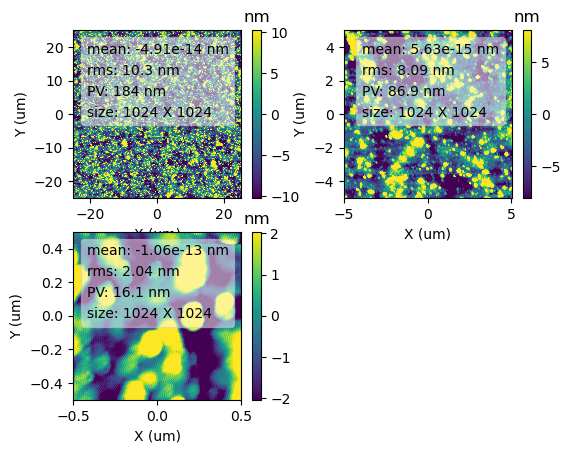

<Figure size 640x480 with 0 Axes>

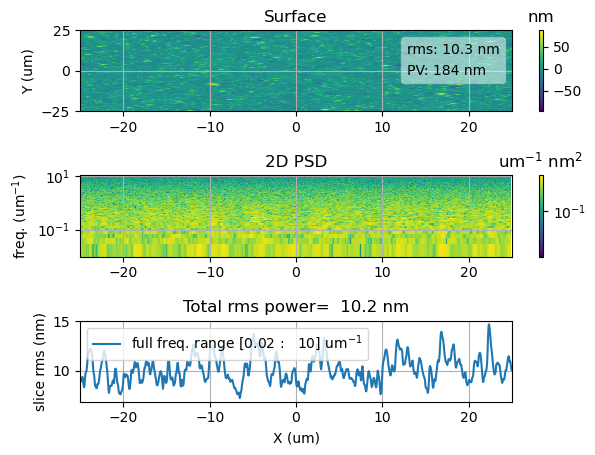

<Figure size 640x480 with 0 Axes>

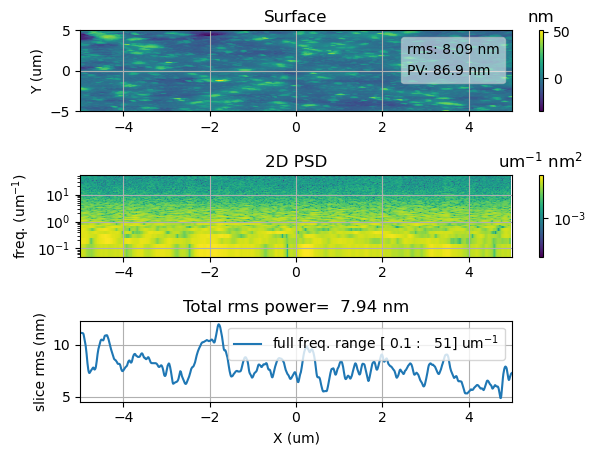

<Figure size 640x480 with 0 Axes>

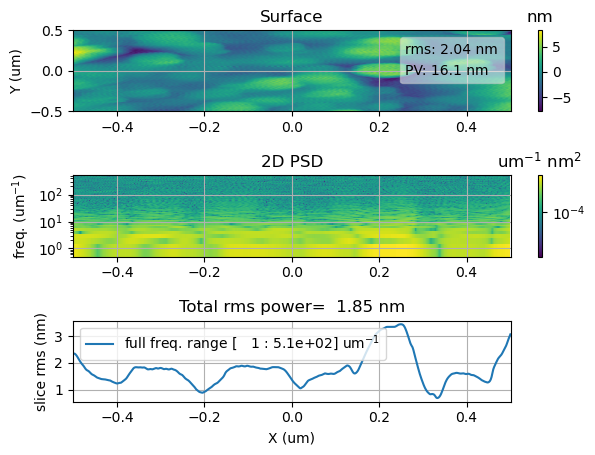

<Figure size 640x480 with 0 Axes>

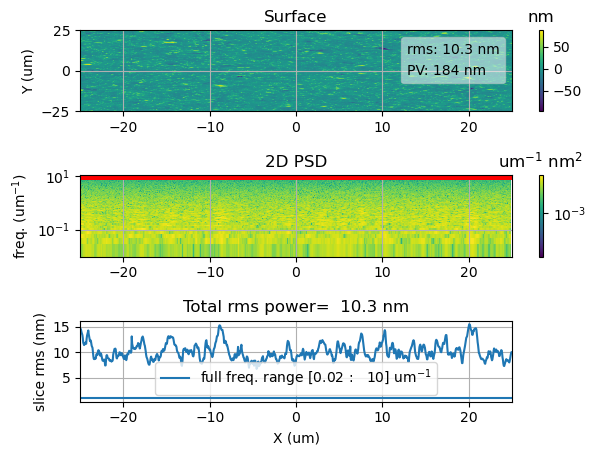

<Figure size 640x480 with 0 Axes>

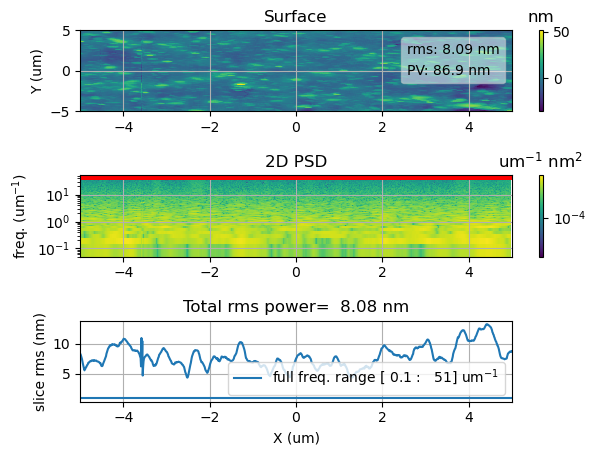

<Figure size 640x480 with 0 Axes>

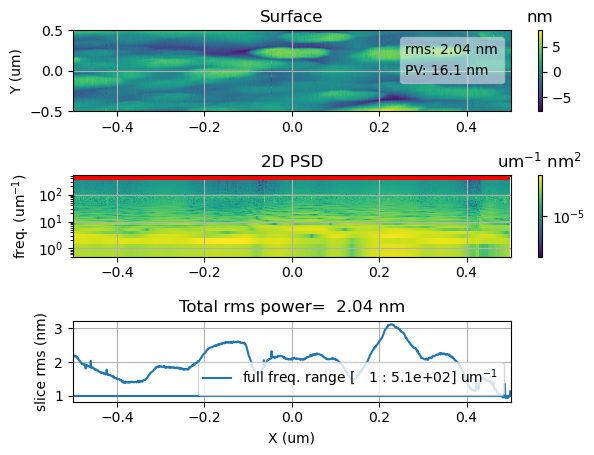

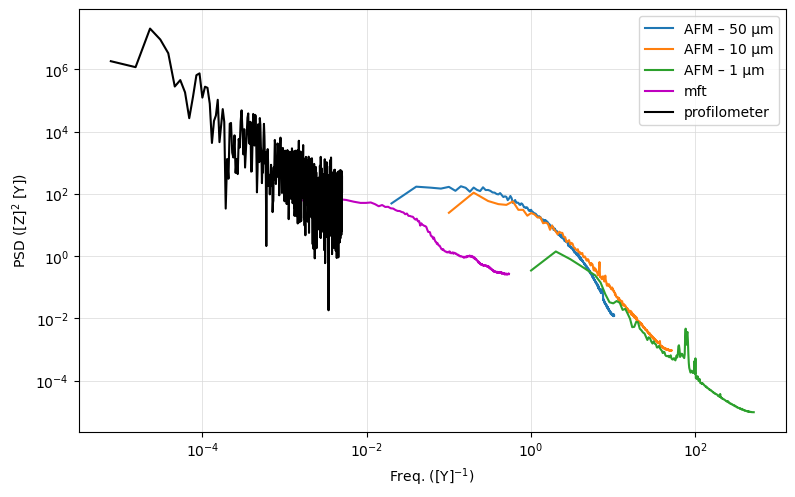

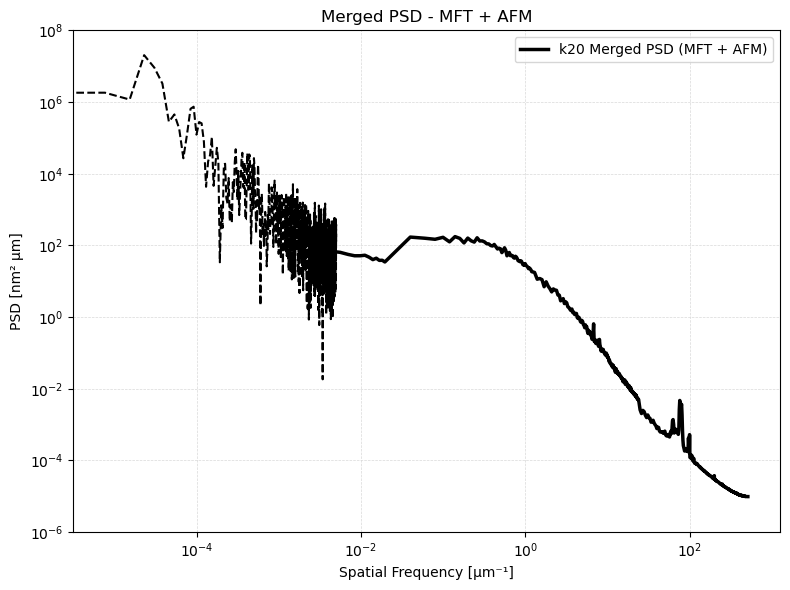

In [ ]:
#K20 mandrel AFM+MFT

#######################################################
#######################################################

#loading data
datafolder = r'/home/varun/PSD_AFM/k20_mandrel_afm'

df = ['Image01801.nid',
      'Image01802.nid',
      'Image01803.nid']
files = [os.path.join(datafolder, f) for f in df]

#files = [os.path.join(datafolder, f) for f in df]
#outdir = r'results'  #os.path.join(datafolder,'results')
#outfolder = outdir 

labels = ['AFM - 1 um', 'AFM - 10 um', 'AFM - 50 um']

#psds = dopsd(files, labels, outfolder)
from pySurf.readers import nid_reader
data  = [read_nid(f) for f in files]
#dl = Dlist(data,units=['um','um','nm'],scale=[1e6,1e6,1e9],center = (0,0))
datalist = Dlist([Data2D(*d,units=['um','um','nm'],scale=[1e6,1e6,1e9],center = (0,0)) for d in data])  #TODO: allow reader

datalist = datalist.level(2,axis=1)
datalist.plot(type = 'grid')  #TOOD: allow figure output 
plt.show()  
afm_datalist = [(d, d.psd(analysis=True).avgpsd()) for d in datalist]


#################################################
#################################################

#plots of afm data

import os, pathlib, numpy as np, matplotlib.pyplot as plt
from pySurf.MIRO_analysis_functions import plot_psd

def psd_to_xy(psd): 
    for fx, fy in [('f','P'), ('x','y'), ('fx','py'), ('fx','P')]:
        if hasattr(psd, fx) and hasattr(psd, fy):
            return getattr(psd, fx), getattr(psd, fy)
    arr = psd.data if hasattr(psd, 'data') else psd
    return (arr[0], arr[1]) if arr.shape[0]==2 else (arr[:,0], arr[:,1])                            

#psd_list = [d.psd(axis=1, analysis=True, rmsthr=1).avgpsd()
#            for d in datalist]

#colors = ['tab:blue', 'tab:orange', 'tab:green']   # 1 µm, 10 µm, 50 µm
#labels = ['AFM – 50 µm', 'AFM – 10 µm', 'AFM – 1 µm']

#plt.figure(figsize=(8,5))
#for psd, c, lab in zip(psd_list, colors, labels):
#    f, P = psd_to_xy(psd)
    #print(f); print(P)
#    plot_psd(f, P, label=lab, color=c)           

#plt.xlabel('Frequenza spaziale [µm⁻¹]')
#plt.ylabel('PSD [nm² µm]')
#plt.grid(True, which='both', color='0.85', lw=0.5)
#plt.legend(loc='upper right')
#plt.tight_layout()                                                

#outdir = pathlib.Path().absolute() / 'AFM_results'
#outdir.mkdir(exist_ok=True)
#png_out = outdir / 'AFM_filtered_all.png'
#plt.savefig(png_out, dpi=300)
#plt.show()

#print('Grafico salvato in:', png_out)


##########################################
psd_list = [d.psd(axis=1, analysis=True, rmsthr=1).avgpsd()
            for d in datalist]

colors = ['tab:blue', 'tab:orange', 'tab:green']   # 1 µm, 10 µm, 50 µm
labels = ['AFM – 50 µm', 'AFM – 10 µm', 'AFM – 1 µm']

plt.figure(figsize=(8,5))
for psd, c, lab in zip(psd_list, colors, labels):
    f, P = psd_to_xy(psd)
    #print(f); print(P)
    plot_psd(f, P, label=lab, color=c)           

plt.xlabel('Frequenza spaziale [µm⁻¹]')
plt.ylabel('PSD [nm² µm]')
plt.grid(True, which='both', color='0.85', lw=0.5)
plt.legend(loc='upper right')
plt.tight_layout()                                                

#outdir = pathlib.Path().absolute() / 'AFM_results'
##outdir.mkdir(exist_ok=True)
#png_out = outdir / 'AFM_filtered_all.png'
#plt.savefig(png_out, dpi=300)
#plt.show()

#print('Grafico salvato in:', png_out)



datafolder = r'/home/varun/PSD_AFM/k20_mandrel_afm'
filelist=['ceramic_mandrel_m2.dat','ceramic_mandrel_m3.dat','ceramic_mandrel_m4.dat']
dataavgk20=[]
for fname in filelist:
    fn = os.path.join(datafolder, fname)
    data, x, y = matrixdat_reader(fn, center=(0, 0), scale=[1000., 1000., 1e9])
    d = Data2D(data, x, y, units=['mm', 'mm', 'nm'], name=os.path.basename(fn))

    # Detrending of order 4
    d4 = d.level(4)
    p2d=d.psd()
    # PSD calculation
    psd_avg = d4.psd().avgpsd()

    # PSD plot
    #psd_avg.plot(label=fname)
    dataavgk20.append(psd_avg)
#print(dataavg006)
#(np.average(dataavg008)).plot(label='008avg', marker='x',units=p2d.units)
psd_avg=np.average(dataavgk20)
#file_singolo = 'ceramic_mandrel_m4.dat'
#fn = os.path.join(datafolder, file_singolo)

#data, x, y = matrixdat_reader(fn, center=(0, 0), scale=[1000., 1000., 1e9])
#d = Data2D(data, x, y, units=['mm', 'mm', 'nm'], name=os.path.basename(fn))

#d4 = d.level(4)#, axis=0)  
#psd_avg = d4.psd().avgpsd()
#psd_avg.plot(); plt.show()

f_single, P_single = psd_to_xy(psd_avg)

# Conversione da [1/mm] a [1/µm] e da [nm²*mm] a [nm²*µm]datafolder = r'/home/varun/PSD_AFM/'
f_single_um = f_single / 1000
P_single_um = P_single * 1000 

plot_psd(f_single_um, P_single_um, label='mft', color='m')
#plt.show()


########################################
########################################
f_single_croc, P_single_croc = psd_to_xy(p2_k20.psd())

# Conversione da [1/mm] a [1/µm] e da [nm²*mm] a [nm²*µm]datafolder = r'/home/varun/PSD_AFM/'
f_single_croc_um_k20 = f_single_croc / 1000
P_single_croc_um_k20 = P_single_croc * 1000 

plot_psd(f_single_croc_um_k20, P_single_croc_um_k20, label='profilometer', color='k')
plt.show()
#################################################
#################################################

#################################################
#################################################

#merged full,single psd

f_1um, P_1um = psd_to_xy(psd_list[2])
f_10um, P_10um = psd_to_xy(psd_list[1])
f_50um, P_50um = psd_to_xy(psd_list[0])
#####################

fmin_mft = 0.02
fmin_10um = 1.2
fmin_1um = 24
min=0.002

# Seleziona i pezzi giusti
mask_mft = (f_single_um <= fmin_mft) & (f_single_um>=min)
mask_50um = (f_50um >= fmin_mft)&(f_50um <= fmin_10um) #aggiungo quei meno per collegarli meglio se no rimane uno spazietto
mask_10um = (f_10um >= fmin_10um)&(f_10um <=fmin_1um )
mask_1um = f_1um >= fmin_1um 

f_merge_mft = f_single_um[mask_mft]
P_merge_mft = P_single_um[mask_mft]

f_merge_50um = f_50um[mask_50um]
P_merge_50um = P_50um[mask_50um]

f_merge_10um = f_10um[mask_10um]
P_merge_10um = P_10um[mask_10um]

f_merge_1um = f_1um[mask_1um]
P_merge_1um = P_1um[mask_1um]
###############################
###############################
# Merge completo

f_merged = np.concatenate([f_merge_mft, f_merge_50um, f_merge_10um, f_merge_1um])
P_merged = np.concatenate([P_merge_mft, P_merge_50um, P_merge_10um, P_merge_1um])

# Ordinamento corretto
order = np.argsort(f_merged)
f_mergedk20 = f_merged[order]
P_mergedk20 = P_merged[order]

#grafico
plt.figure(figsize=(8,6))
plt.loglog(f_single_croc_um_k20, P_single_croc_um_k20, ls='--', color='k')
plt.loglog(f_mergedk20, P_mergedk20, color='k', lw=2.5, label='k20 Merged PSD (MFT + AFM)')
plt.xlabel('Spatial Frequency [µm⁻¹]')
plt.ylabel('PSD [nm² µm]')
plt.grid(True, which='both', linestyle='--', color='0.85', lw=0.5)
plt.ylim(1e-6,1e8)
plt.legend()
plt.title('Merged PSD - MFT + AFM')
plt.tight_layout()
plt.show()


<Figure size 640x480 with 0 Axes>

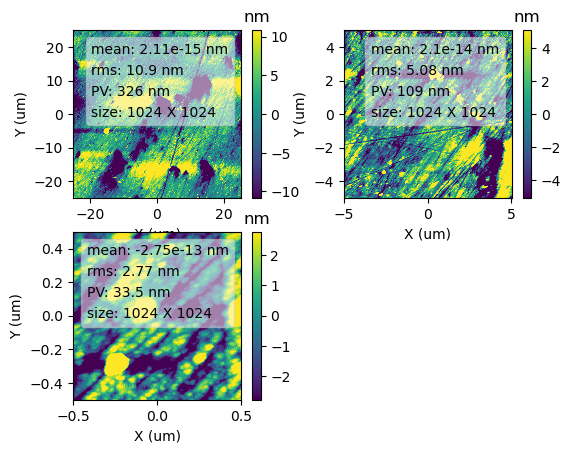

<Figure size 640x480 with 0 Axes>

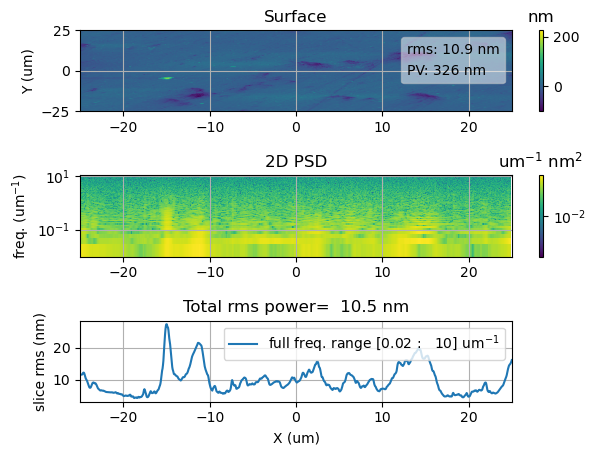

<Figure size 640x480 with 0 Axes>

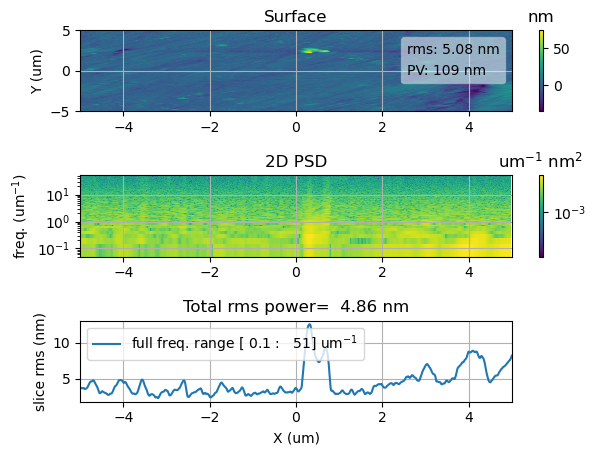

<Figure size 640x480 with 0 Axes>

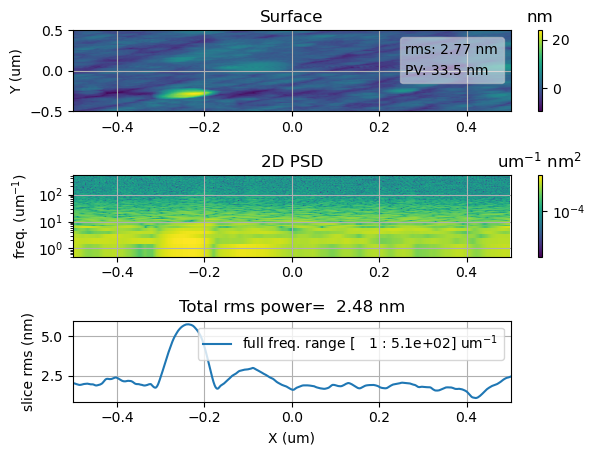

<Figure size 640x480 with 0 Axes>

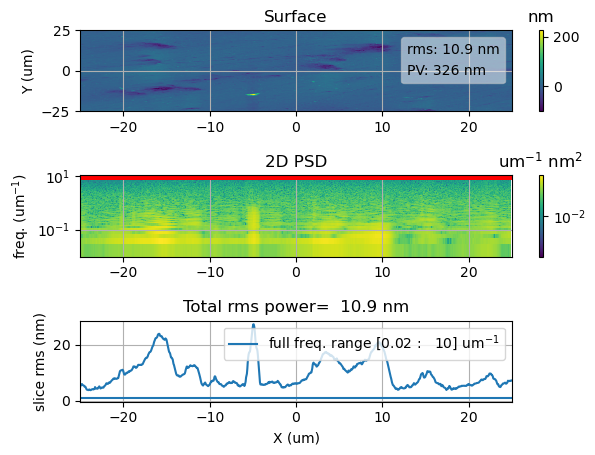

<Figure size 640x480 with 0 Axes>

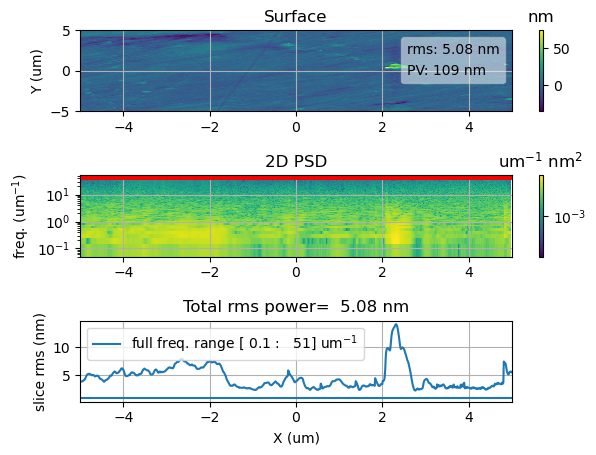

<Figure size 640x480 with 0 Axes>

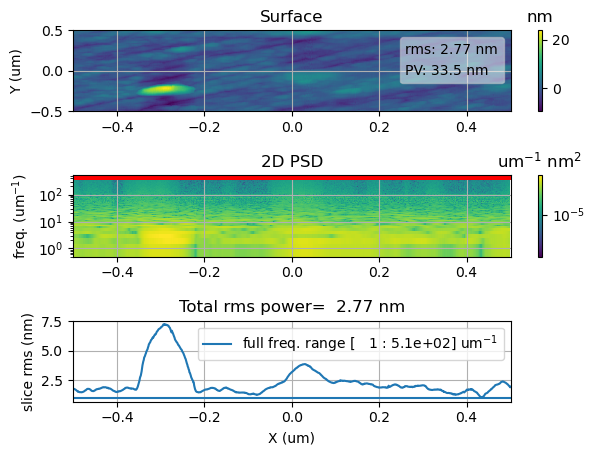

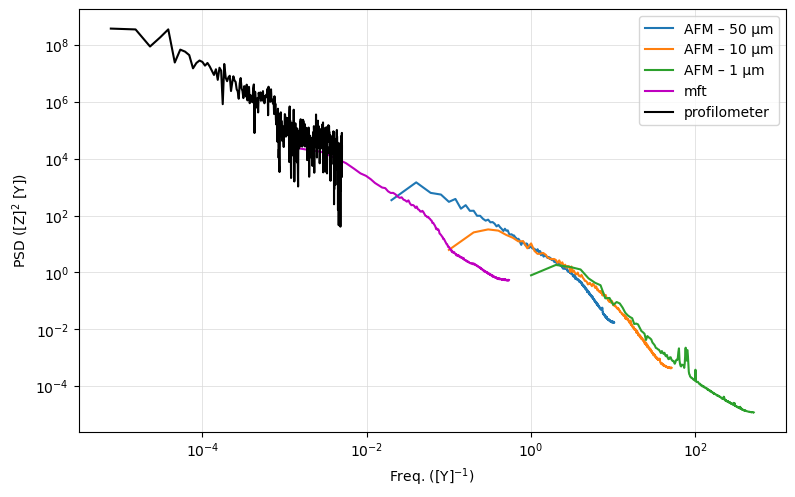

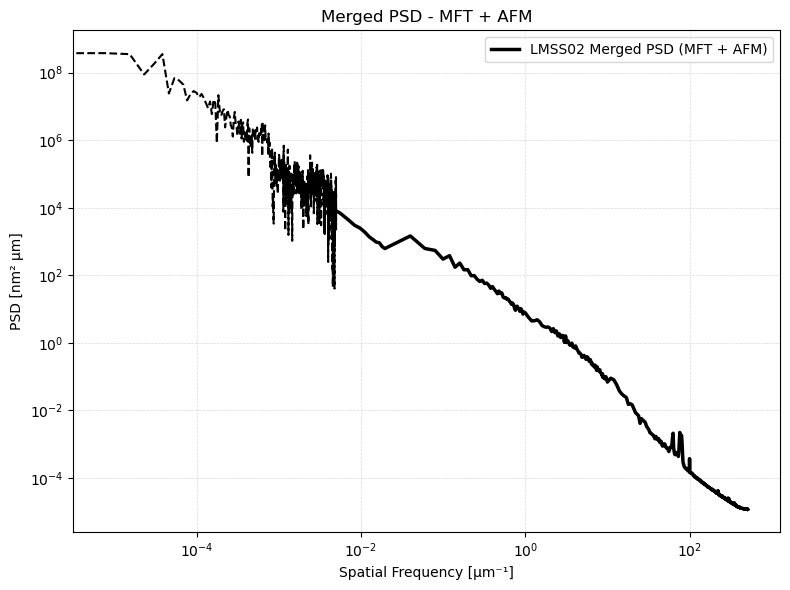

In [ ]:
#LMSS02 mandrel AFM+MFT

#######################################################
#######################################################

#loading data
datafolder = r'/home/varun/PSD_AFM/lmss02_mandrel_afm'

df = ['Image01815.nid',
      'Image01816.nid',
      'Image01817.nid']
files = [os.path.join(datafolder, f) for f in df]

#files = [os.path.join(datafolder, f) for f in df]
#outdir = r'results'  #os.path.join(datafolder,'results')
#outfolder = outdir 

labels = ['AFM - 1 um', 'AFM - 10 um', 'AFM - 50 um']

#psds = dopsd(files, labels, outfolder)
from pySurf.readers import nid_reader
data  = [read_nid(f) for f in files]
#dl = Dlist(data,units=['um','um','nm'],scale=[1e6,1e6,1e9],center = (0,0))
datalist = Dlist([Data2D(*d,units=['um','um','nm'],scale=[1e6,1e6,1e9],center = (0,0)) for d in data])  #TODO: allow reader

datalist = datalist.level(2,axis=1)
datalist.plot(type = 'grid')  #TOOD: allow figure output 
plt.show()  
afm_datalist = [(d, d.psd(analysis=True).avgpsd()) for d in datalist]


#################################################
#################################################

#plots of afm data

import os, pathlib, numpy as np, matplotlib.pyplot as plt
from pySurf.MIRO_analysis_functions import plot_psd

def psd_to_xy(psd): 
    for fx, fy in [('f','P'), ('x','y'), ('fx','py'), ('fx','P')]:
        if hasattr(psd, fx) and hasattr(psd, fy):
            return getattr(psd, fx), getattr(psd, fy)
    arr = psd.data if hasattr(psd, 'data') else psd
    return (arr[0], arr[1]) if arr.shape[0]==2 else (arr[:,0], arr[:,1])                            

#psd_list = [d.psd(axis=1, analysis=True, rmsthr=1).avgpsd()
#            for d in datalist]

#colors = ['tab:blue', 'tab:orange', 'tab:green']   # 1 µm, 10 µm, 50 µm
#labels = ['AFM – 50 µm', 'AFM – 10 µm', 'AFM – 1 µm']

#plt.figure(figsize=(8,5))
#for psd, c, lab in zip(psd_list, colors, labels):
#    f, P = psd_to_xy(psd)
    #print(f); print(P)
#    plot_psd(f, P, label=lab, color=c)           

#plt.xlabel('Frequenza spaziale [µm⁻¹]')
#plt.ylabel('PSD [nm² µm]')
#plt.grid(True, which='both', color='0.85', lw=0.5)
#plt.legend(loc='upper right')
#plt.tight_layout()                                                

#outdir = pathlib.Path().absolute() / 'AFM_results'
#outdir.mkdir(exist_ok=True)
#png_out = outdir / 'AFM_filtered_all.png'
#plt.savefig(png_out, dpi=300)
#plt.show()

#print('Grafico salvato in:', png_out)


##########################################
psd_list = [d.psd(axis=1, analysis=True, rmsthr=1).avgpsd()
            for d in datalist]

colors = ['tab:blue', 'tab:orange', 'tab:green']   # 1 µm, 10 µm, 50 µm
labels = ['AFM – 50 µm', 'AFM – 10 µm', 'AFM – 1 µm']

plt.figure(figsize=(8,5))
for psd, c, lab in zip(psd_list, colors, labels):
    f, P = psd_to_xy(psd)
    #print(f); print(P)
    plot_psd(f, P, label=lab, color=c)           

plt.xlabel('Frequenza spaziale [µm⁻¹]')
plt.ylabel('PSD [nm² µm]')
plt.grid(True, which='both', color='0.85', lw=0.5)
plt.legend(loc='upper right')
plt.tight_layout()                                                

#outdir = pathlib.Path().absolute() / 'AFM_results'
##outdir.mkdir(exist_ok=True)
#png_out = outdir / 'AFM_filtered_all.png'
#plt.savefig(png_out, dpi=300)
#plt.show()

#print('Grafico salvato in:', png_out)



datafolder = r'/home/varun/PSD_AFM/lmss02_mandrel_afm'
filelist=['LMSS02_m1.dat','LMSS02_m2.dat','LMSS02_m3.dat']
dataavginox=[]
for fname in filelist:
    fn = os.path.join(datafolder, fname)
    data, x, y = matrixdat_reader(fn, center=(0, 0), scale=[1000., 1000., 1e9])
    d = Data2D(data, x, y, units=['mm', 'mm', 'nm'], name=os.path.basename(fn))

    # Detrending of order 4
    d4 = d.level(4)
    p2d=d.psd()
    # PSD calculation
    psd_avg = d4.psd().avgpsd()

    # PSD plot
    #psd_avg.plot(label=fname)
    dataavginox.append(psd_avg)
#print(dataavg006)
#(np.average(dataavg008)).plot(label='008avg', marker='x',units=p2d.units)
psd_avg=np.average(dataavginox)
#file_singolo = 'ceramic_mandrel_m4.dat'
#fn = os.path.join(datafolder, file_singolo)

#data, x, y = matrixdat_reader(fn, center=(0, 0), scale=[1000., 1000., 1e9])
#d = Data2D(data, x, y, units=['mm', 'mm', 'nm'], name=os.path.basename(fn))

#d4 = d.level(4)#, axis=0)  
#psd_avg = d4.psd().avgpsd()
#psd_avg.plot(); plt.show()

f_single, P_single = psd_to_xy(psd_avg)

# Conversione da [1/mm] a [1/µm] e da [nm²*mm] a [nm²*µm]datafolder = r'/home/varun/PSD_AFM/'
f_single_um = f_single / 1000
P_single_um = P_single * 1000 

plot_psd(f_single_um, P_single_um, label='mft', color='m')
#plt.show()


########################################
########################################
f_single_croc, P_single_croc = psd_to_xy(p2_inox.psd())

# Conversione da [1/mm] a [1/µm] e da [nm²*mm] a [nm²*µm]datafolder = r'/home/varun/PSD_AFM/'
f_single_croc_um_inox = f_single_croc / 1000
P_single_croc_um_inox = P_single_croc * 1000 

plot_psd(f_single_croc_um_inox, P_single_croc_um_inox, label='profilometer', color='k')
plt.show()
#################################################
#################################################

#################################################
#################################################

#merged full,single psd

f_1um, P_1um = psd_to_xy(psd_list[2])
f_10um, P_10um = psd_to_xy(psd_list[1])
f_50um, P_50um = psd_to_xy(psd_list[0])
#####################

fmin_mft = 0.02
fmin_10um = 1
fmin_1um = 10
min=0.002

# Seleziona i pezzi giusti
mask_mft = (f_single_um <= fmin_mft) & (f_single_um>=min)
mask_50um = (f_50um >= fmin_mft)&(f_50um <= fmin_10um) #aggiungo quei meno per collegarli meglio se no rimane uno spazietto
mask_10um = (f_10um >= fmin_10um)&(f_10um <=fmin_1um )
mask_1um = f_1um >= fmin_1um 

f_merge_mft = f_single_um[mask_mft]
P_merge_mft = P_single_um[mask_mft]

f_merge_50um = f_50um[mask_50um]
P_merge_50um = P_50um[mask_50um]

f_merge_10um = f_10um[mask_10um]
P_merge_10um = P_10um[mask_10um]

f_merge_1um = f_1um[mask_1um]
P_merge_1um = P_1um[mask_1um]
###############################
###############################
# Merge completo

f_merged = np.concatenate([f_merge_mft, f_merge_50um, f_merge_10um, f_merge_1um])
P_merged = np.concatenate([P_merge_mft, P_merge_50um, P_merge_10um, P_merge_1um])

# Ordinamento corretto
order = np.argsort(f_merged)
f_mergedinox = f_merged[order]
P_mergedinox = P_merged[order]

#grafico
plt.figure(figsize=(8,6))
plt.loglog(f_single_croc_um_inox, P_single_croc_um_inox, ls='--', color='k')
plt.loglog(f_mergedinox, P_mergedinox, color='k', lw=2.5, label='LMSS02 Merged PSD (MFT + AFM)')
plt.xlabel('Spatial Frequency [µm⁻¹]')
plt.ylabel('PSD [nm² µm]')
plt.grid(True, which='both', linestyle='--', color='0.85', lw=0.5)
#plt.ylim(1e-6,1e8)
plt.legend()
plt.title('Merged PSD - MFT + AFM')
plt.tight_layout()
plt.show()


<Figure size 640x480 with 0 Axes>

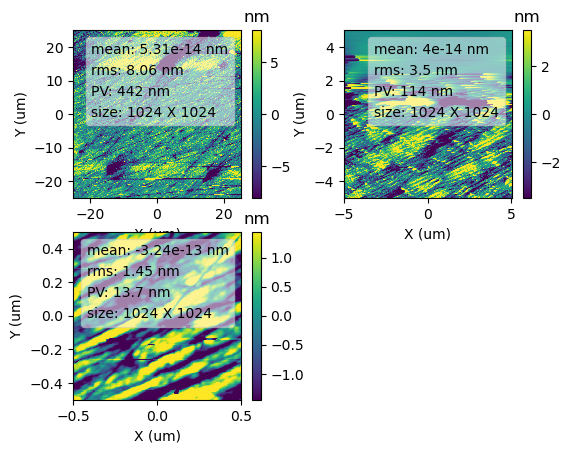

<Figure size 640x480 with 0 Axes>

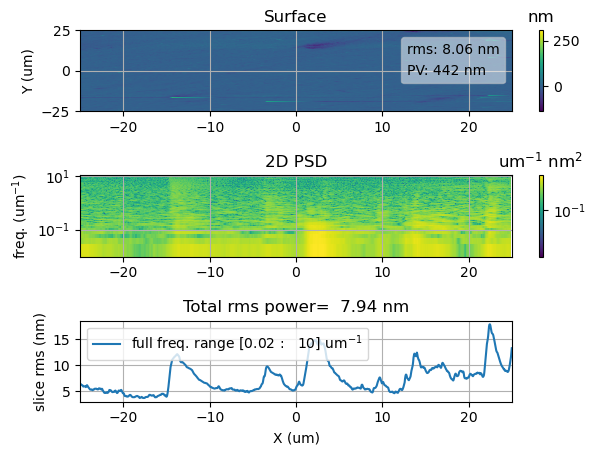

<Figure size 640x480 with 0 Axes>

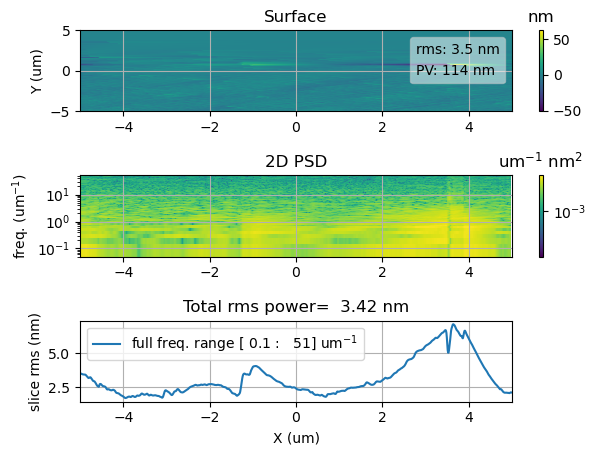

<Figure size 640x480 with 0 Axes>

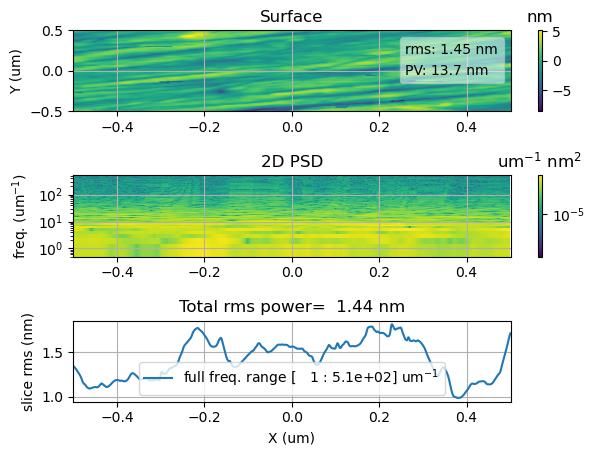

<Figure size 640x480 with 0 Axes>

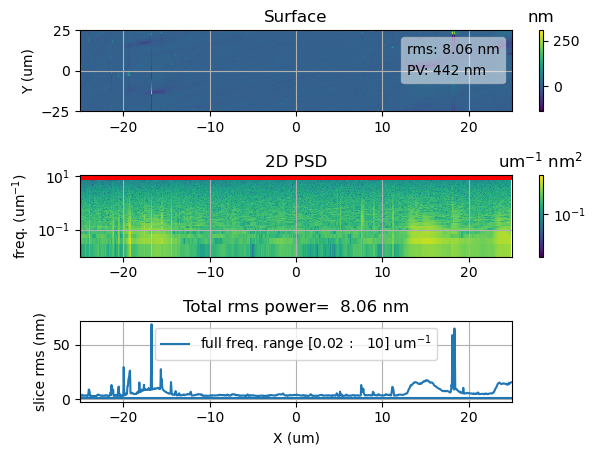

<Figure size 640x480 with 0 Axes>

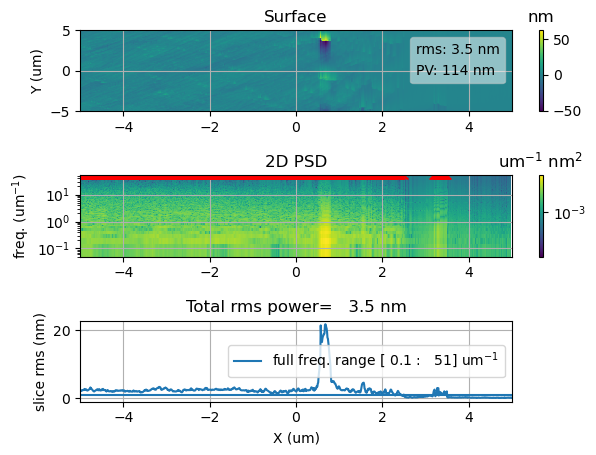

<Figure size 640x480 with 0 Axes>

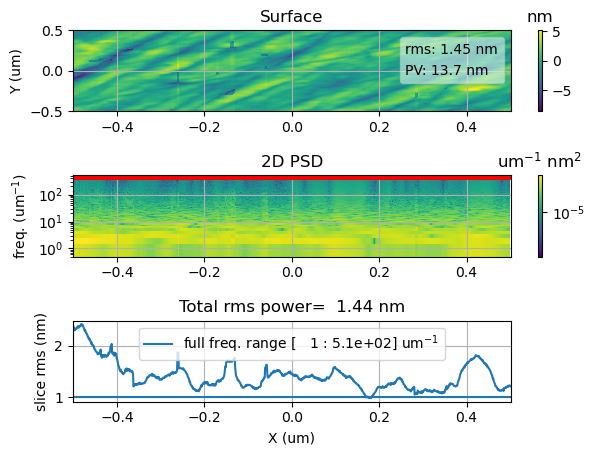

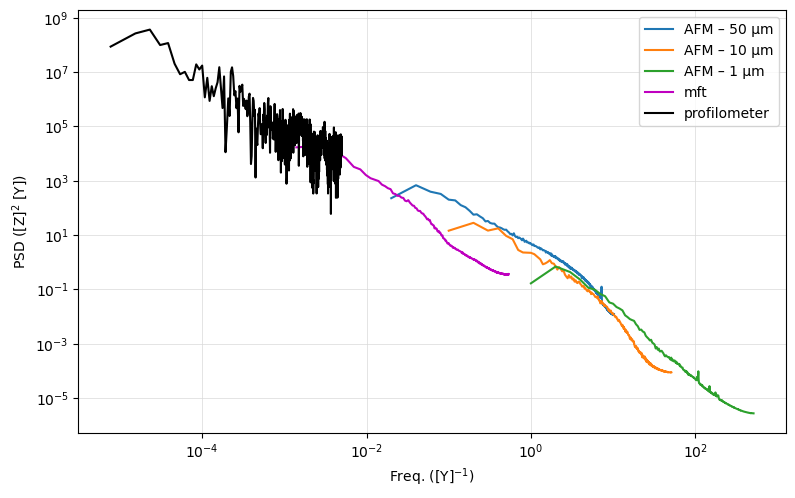

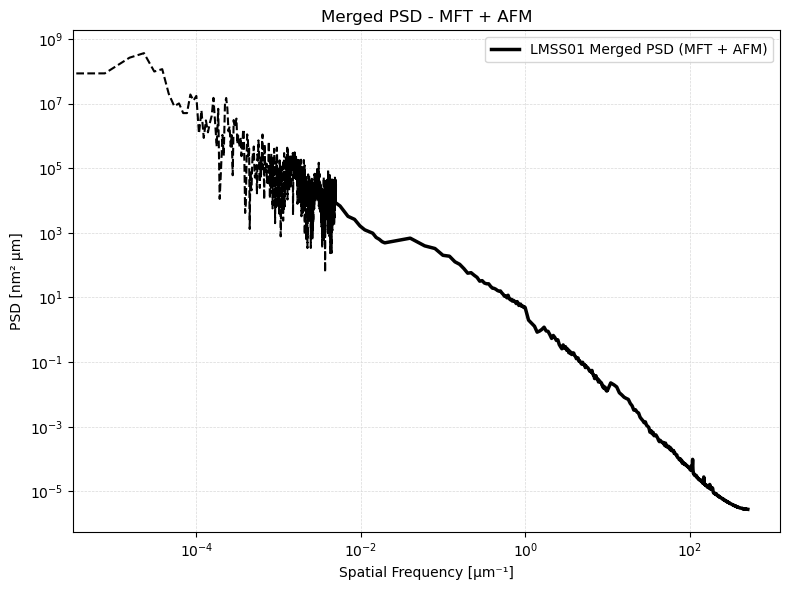

In [ ]:
#LMSS01 mandrel AFM+MFT

#######################################################
#######################################################

#loading data
datafolder = r'/home/varun/PSD_AFM/lmss01_mandrel_afm'

df = ['Image01965.nid',
      'Image01964.nid',
      'Image01970.nid']
files = [os.path.join(datafolder, f) for f in df]

#files = [os.path.join(datafolder, f) for f in df]
#outdir = r'results'  #os.path.join(datafolder,'results')
#outfolder = outdir 

labels = ['AFM - 1 um', 'AFM - 10 um', 'AFM - 50 um']

#psds = dopsd(files, labels, outfolder)
from pySurf.readers import nid_reader
data  = [read_nid(f) for f in files]
#dl = Dlist(data,units=['um','um','nm'],scale=[1e6,1e6,1e9],center = (0,0))
datalist = Dlist([Data2D(*d,units=['um','um','nm'],scale=[1e6,1e6,1e9],center = (0,0)) for d in data])  #TODO: allow reader

datalist = datalist.level(2,axis=1)
datalist.plot(type = 'grid')  #TOOD: allow figure output 
plt.show()  
afm_datalist = [(d, d.psd(analysis=True).avgpsd()) for d in datalist]


#################################################
#################################################

#plots of afm data

import os, pathlib, numpy as np, matplotlib.pyplot as plt
from pySurf.MIRO_analysis_functions import plot_psd

def psd_to_xy(psd): 
    for fx, fy in [('f','P'), ('x','y'), ('fx','py'), ('fx','P')]:
        if hasattr(psd, fx) and hasattr(psd, fy):
            return getattr(psd, fx), getattr(psd, fy)
    arr = psd.data if hasattr(psd, 'data') else psd
    return (arr[0], arr[1]) if arr.shape[0]==2 else (arr[:,0], arr[:,1])                            

#psd_list = [d.psd(axis=1, analysis=True, rmsthr=1).avgpsd()
#            for d in datalist]

#colors = ['tab:blue', 'tab:orange', 'tab:green']   # 1 µm, 10 µm, 50 µm
#labels = ['AFM – 50 µm', 'AFM – 10 µm', 'AFM – 1 µm']

#plt.figure(figsize=(8,5))
#for psd, c, lab in zip(psd_list, colors, labels):
#    f, P = psd_to_xy(psd)
    #print(f); print(P)
#    plot_psd(f, P, label=lab, color=c)           

#plt.xlabel('Frequenza spaziale [µm⁻¹]')
#plt.ylabel('PSD [nm² µm]')
#plt.grid(True, which='both', color='0.85', lw=0.5)
#plt.legend(loc='upper right')
#plt.tight_layout()                                                

#outdir = pathlib.Path().absolute() / 'AFM_results'
#outdir.mkdir(exist_ok=True)
#png_out = outdir / 'AFM_filtered_all.png'
#plt.savefig(png_out, dpi=300)
#plt.show()

#print('Grafico salvato in:', png_out)


##########################################
psd_list = [d.psd(axis=1, analysis=True, rmsthr=1).avgpsd()
            for d in datalist]

colors = ['tab:blue', 'tab:orange', 'tab:green']   # 1 µm, 10 µm, 50 µm
labels = ['AFM – 50 µm', 'AFM – 10 µm', 'AFM – 1 µm']

plt.figure(figsize=(8,5))
for psd, c, lab in zip(psd_list, colors, labels):
    f, P = psd_to_xy(psd)
    #print(f); print(P)
    plot_psd(f, P, label=lab, color=c)           

plt.xlabel('Frequenza spaziale [µm⁻¹]')
plt.ylabel('PSD [nm² µm]')
plt.grid(True, which='both', color='0.85', lw=0.5)
plt.legend(loc='upper right')
plt.tight_layout()                                                

#outdir = pathlib.Path().absolute() / 'AFM_results'
##outdir.mkdir(exist_ok=True)
#png_out = outdir / 'AFM_filtered_all.png'
#plt.savefig(png_out, dpi=300)
#plt.show()

#print('Grafico salvato in:', png_out)



datafolder = r'/home/varun/PSD_AFM/lmss01_mandrel_afm'
filelist=['LMSS01_m1.dat','LMSS01_m2.dat','LMSS01_m3.dat']
dataavglmss01=[]
for fname in filelist:
    fn = os.path.join(datafolder, fname)
    data, x, y = matrixdat_reader(fn, center=(0, 0), scale=[1000., 1000., 1e9])
    d = Data2D(data, x, y, units=['mm', 'mm', 'nm'], name=os.path.basename(fn))

    # Detrending of order 4
    d4 = d.level(4)
    p2d=d.psd()
    # PSD calculation
    psd_avg = d4.psd().avgpsd()

    # PSD plot
    #psd_avg.plot(label=fname)
    dataavglmss01.append(psd_avg)
#print(dataavg006)
#(np.average(dataavg008)).plot(label='008avg', marker='x',units=p2d.units)
psd_avg=np.average(dataavglmss01)
#file_singolo = 'ceramic_mandrel_m4.dat'
#fn = os.path.join(datafolder, file_singolo)

#data, x, y = matrixdat_reader(fn, center=(0, 0), scale=[1000., 1000., 1e9])
#d = Data2D(data, x, y, units=['mm', 'mm', 'nm'], name=os.path.basename(fn))

#d4 = d.level(4)#, axis=0)  
#psd_avg = d4.psd().avgpsd()
#psd_avg.plot(); plt.show()

f_single, P_single = psd_to_xy(psd_avg)

# Conversione da [1/mm] a [1/µm] e da [nm²*mm] a [nm²*µm]datafolder = r'/home/varun/PSD_AFM/'
f_single_um = f_single / 1000
P_single_um = P_single * 1000 

plot_psd(f_single_um, P_single_um, label='mft', color='m')
#plt.show()


########################################
########################################
f_single_croc, P_single_croc = psd_to_xy(p2_lmss01.psd())

# Conversione da [1/mm] a [1/µm] e da [nm²*mm] a [nm²*µm]datafolder = r'/home/varun/PSD_AFM/'
f_single_croc_um_lmss01 = f_single_croc / 1000
P_single_croc_um_lmss01 = P_single_croc * 1000 

plot_psd(f_single_croc_um_lmss01, P_single_croc_um_lmss01, label='profilometer', color='k')
plt.show()
#################################################
#################################################

#################################################
#################################################

#merged full,single psd

f_1um, P_1um = psd_to_xy(psd_list[2])
f_10um, P_10um = psd_to_xy(psd_list[1])
f_50um, P_50um = psd_to_xy(psd_list[0])
#####################

fmin_mft = 0.02
fmin_10um = 1
fmin_1um = 10
min=0.002

# Seleziona i pezzi giusti
mask_mft = (f_single_um <= fmin_mft) & (f_single_um>=min)
mask_50um = (f_50um >= fmin_mft)&(f_50um <= fmin_10um) #aggiungo quei meno per collegarli meglio se no rimane uno spazietto
mask_10um = (f_10um >= fmin_10um)&(f_10um <=fmin_1um )
mask_1um = f_1um >= fmin_1um 

f_merge_mft = f_single_um[mask_mft]
P_merge_mft = P_single_um[mask_mft]

f_merge_50um = f_50um[mask_50um]
P_merge_50um = P_50um[mask_50um]

f_merge_10um = f_10um[mask_10um]
P_merge_10um = P_10um[mask_10um]

f_merge_1um = f_1um[mask_1um]
P_merge_1um = P_1um[mask_1um]
###############################
###############################
# Merge completo

f_merged = np.concatenate([f_merge_mft, f_merge_50um, f_merge_10um, f_merge_1um])
P_merged = np.concatenate([P_merge_mft, P_merge_50um, P_merge_10um, P_merge_1um])

# Ordinamento corretto
order = np.argsort(f_merged)
f_mergedlmss01 = f_merged[order]
P_mergedlmss01 = P_merged[order]

#grafico
plt.figure(figsize=(8,6))
plt.loglog(f_single_croc_um_lmss01, P_single_croc_um_lmss01, ls='--', color='k')
plt.loglog(f_mergedlmss01, P_mergedlmss01, color='k', lw=2.5, label='LMSS01 Merged PSD (MFT + AFM)')
plt.xlabel('Spatial Frequency [µm⁻¹]')
plt.ylabel('PSD [nm² µm]')
plt.grid(True, which='both', linestyle='--', color='0.85', lw=0.5)
#plt.ylim(1e-6,1e8)
plt.legend()
plt.title('Merged PSD - MFT + AFM')
plt.tight_layout()
plt.show()


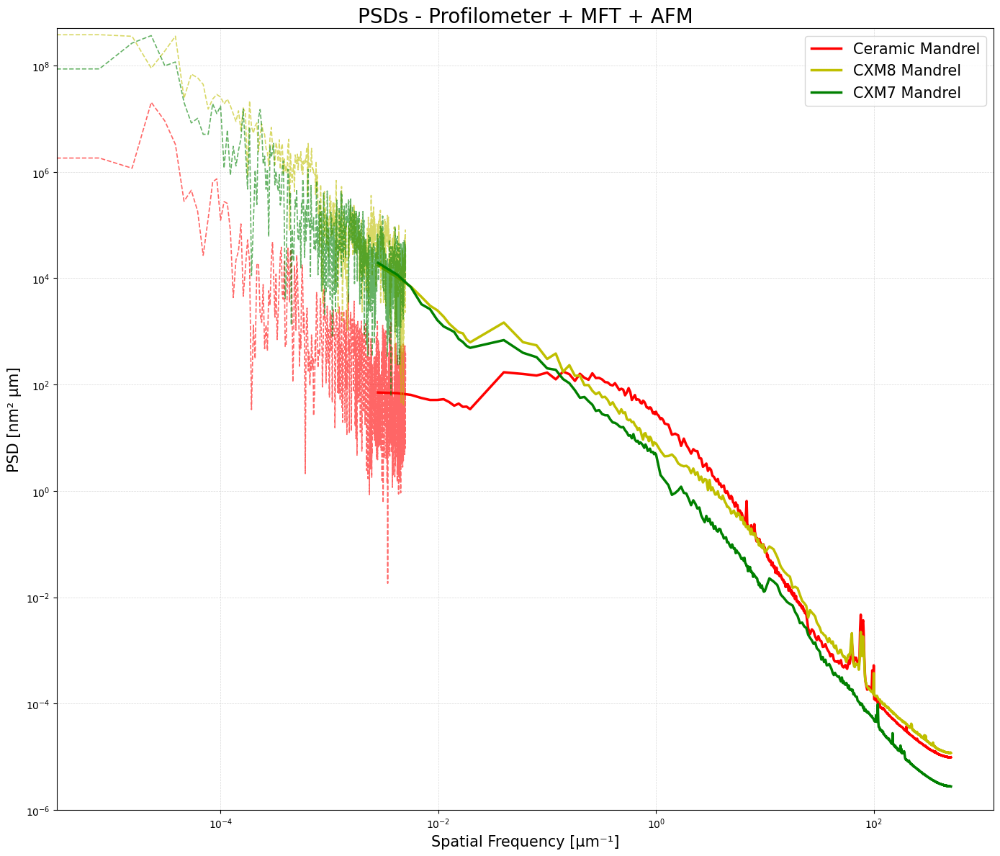

In [ ]:
#Graphic 

plt.figure(figsize=(14,12))

#plt.loglog(f_mergedWafer, P_mergedWafer, color='y', ls='--', lw=2.5, label='Silicon Wafer')

plt.loglog(f_single_croc_um_k20, P_single_croc_um_k20, ls='--', lw=1.2,color='r',alpha=0.6)
plt.loglog(f_mergedk20, P_mergedk20, color='r', lw=2.5, label='Ceramic Mandrel')

plt.loglog(f_single_croc_um_inox, P_single_croc_um_inox, ls='--', lw=1.2,color='y',alpha=0.6)
plt.loglog(f_mergedinox, P_mergedinox, color='y', lw=2.5, label='CXM8 Mandrel')


plt.loglog(f_single_croc_um_lmss01, P_single_croc_um_lmss01, ls='--', lw=1.2,color='g',alpha=0.6)
plt.loglog(f_mergedlmss01, P_mergedlmss01, color='g', lw=2.5, label='CXM7 Mandrel')

#plt.loglog(f_single_croc_um_vp, P_single_croc_um_vp, ls='--', lw=1.2, color='k')
#plt.loglog(f_mergedVP, P_mergedVP, color='k', ls='--', lw=2.5, label='Unslumped Glass')

#plt.loglog(f_single_croc_um_007, P_single_croc_um_007, ls='--', lw=1.2, color='b',alpha=0.4)
#plt.loglog(f_merged007, P_merged007, color='b', lw=2.5, label='Slumped Glass 007')



plt.ylim(1e-6,5e8)
plt.xlabel('Spatial Frequency [µm⁻¹]',fontsize=15)
plt.ylabel('PSD [nm² µm]',fontsize=15)
plt.grid(True, which='both', linestyle='--', color='0.85', lw=0.5)
plt.legend(fontsize=15)
plt.title('PSDs - Profilometer + MFT + AFM',fontsize=20)
plt.tight_layout()
#plt.vlines(0.005,1e-10 , 1e8,ls='--',color='k')
#plt.vlines(1.0,1e-10 , 5e8,ls='--',color='k')
plt.show()


In [ ]:
#AFM+MFT plots for RTM mandrels

<Figure size 640x480 with 0 Axes>

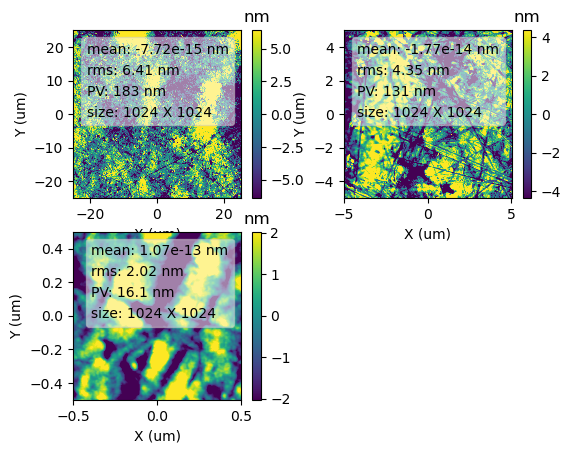

<Figure size 640x480 with 0 Axes>

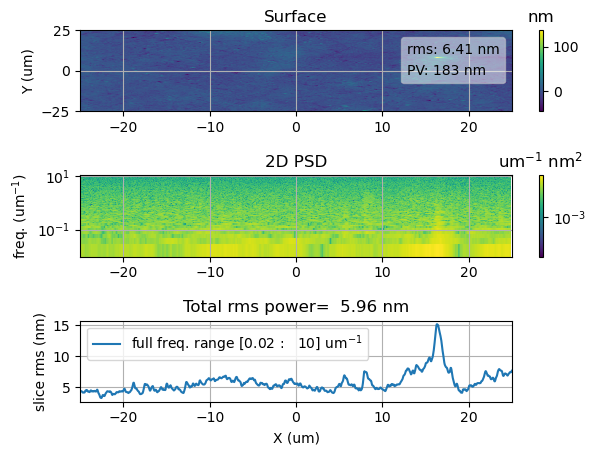

<Figure size 640x480 with 0 Axes>

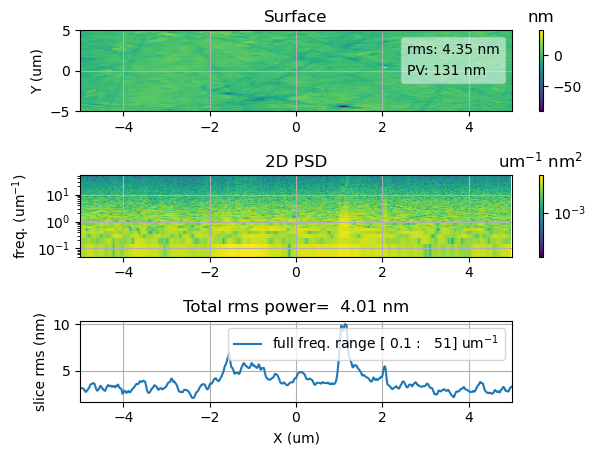

<Figure size 640x480 with 0 Axes>

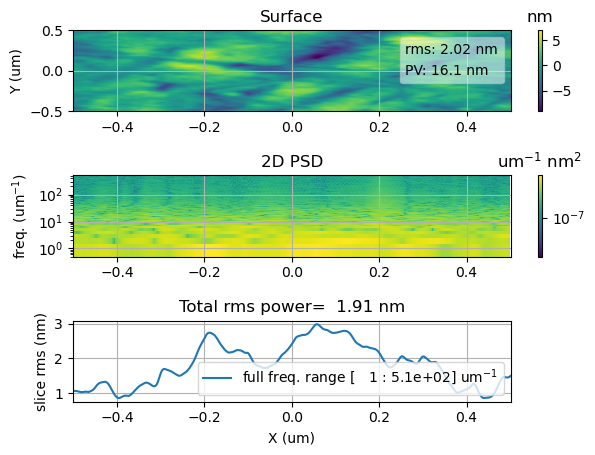

<Figure size 640x480 with 0 Axes>

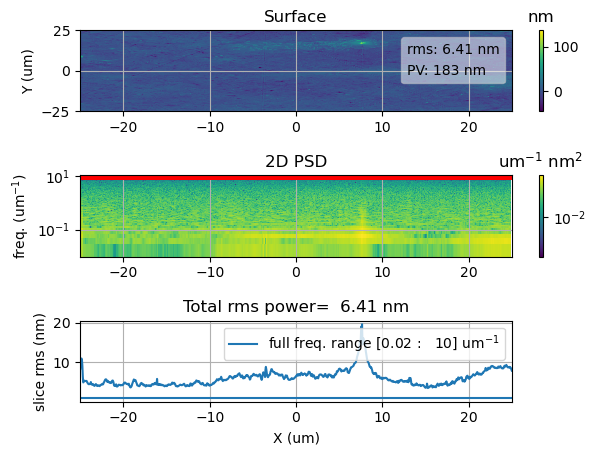

<Figure size 640x480 with 0 Axes>

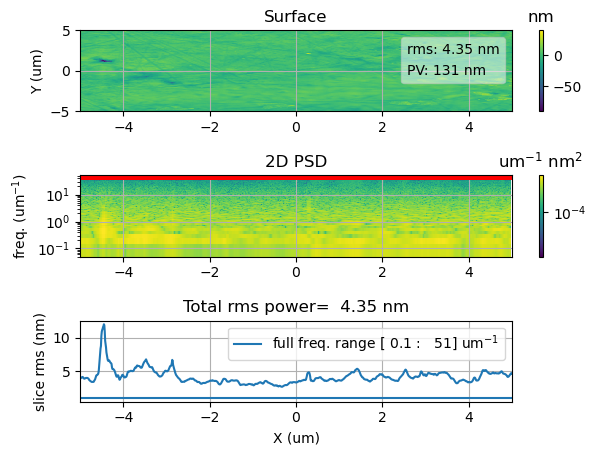

<Figure size 640x480 with 0 Axes>

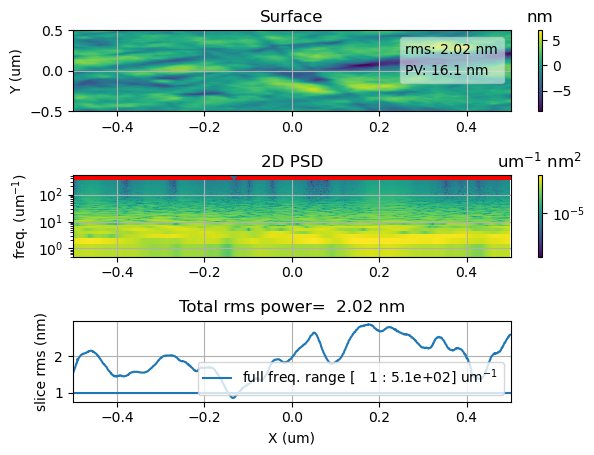

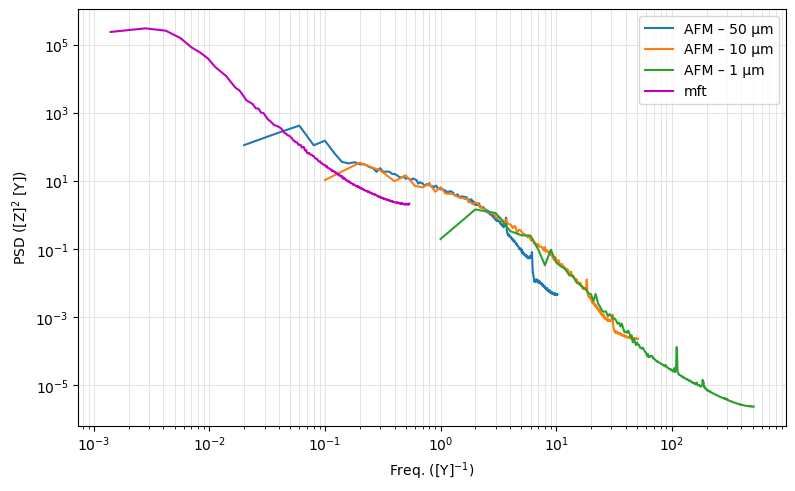

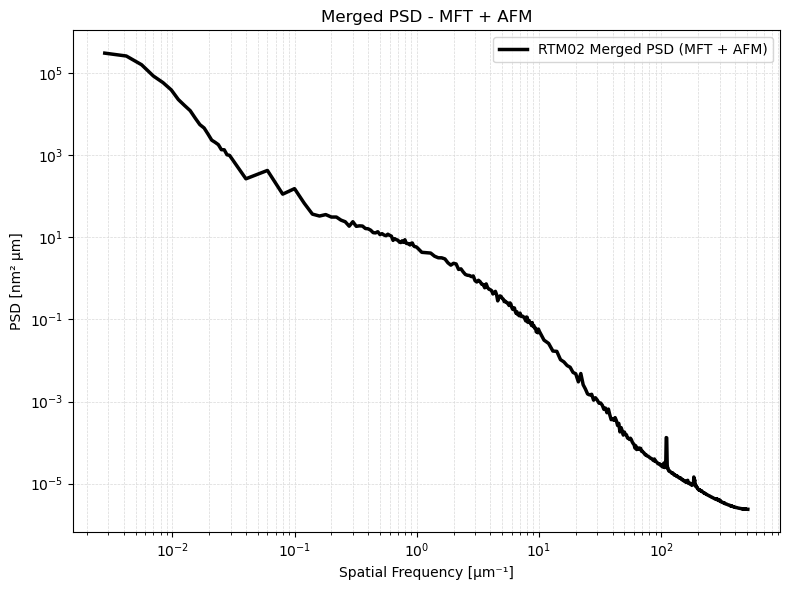

In [ ]:
#RTM02 AFM+MFT

#######################################################
#######################################################

#loading data
datafolder = r'/home/varun/PSD_AFM/RTM02_afm/' 
df = ['Image01949.nid',
      'Image01951.nid',
      'Image01952.nid']
files = [os.path.join(datafolder, f) for f in df]

#files = [os.path.join(datafolder, f) for f in df]
#outdir = r'results'  #os.path.join(datafolder,'results')
#outfolder = outdir 

labels = ['AFM - 1 um', 'AFM - 10 um', 'AFM - 50 um']

#psds = dopsd(files, labels, outfolder)
from pySurf.readers import nid_reader
data  = [read_nid(f) for f in files]
#dl = Dlist(data,units=['um','um','nm'],scale=[1e6,1e6,1e9],center = (0,0))
datalist = Dlist([Data2D(*d,units=['um','um','nm'],scale=[1e6,1e6,1e9],center = (0,0)) for d in data])  #TODO: allow reader

datalist = datalist.level(2,axis=1)
datalist.plot(type = 'grid')  #TOOD: allow figure output 
plt.show()  
afm_datalist = [(d, d.psd(analysis=True).avgpsd()) for d in datalist]


#################################################
#################################################

#plots of afm data

import os, pathlib, numpy as np, matplotlib.pyplot as plt
from pySurf.MIRO_analysis_functions import plot_psd

def psd_to_xy(psd): 
    for fx, fy in [('f','P'), ('x','y'), ('fx','py'), ('fx','P')]:
        if hasattr(psd, fx) and hasattr(psd, fy):
            return getattr(psd, fx), getattr(psd, fy)
    arr = psd.data if hasattr(psd, 'data') else psd
    return (arr[0], arr[1]) if arr.shape[0]==2 else (arr[:,0], arr[:,1])                            

#psd_list = [d.psd(axis=1, analysis=True, rmsthr=1).avgpsd()
#            for d in datalist]

#colors = ['tab:blue', 'tab:orange', 'tab:green']   # 1 µm, 10 µm, 50 µm
#labels = ['AFM – 50 µm', 'AFM – 10 µm', 'AFM – 1 µm']

#plt.figure(figsize=(8,5))
#for psd, c, lab in zip(psd_list, colors, labels):
#    f, P = psd_to_xy(psd)
    #print(f); print(P)
#    plot_psd(f, P, label=lab, color=c)           

#plt.xlabel('Frequenza spaziale [µm⁻¹]')
#plt.ylabel('PSD [nm² µm]')
#plt.grid(True, which='both', color='0.85', lw=0.5)
#plt.legend(loc='upper right')
#plt.tight_layout()                                                

#outdir = pathlib.Path().absolute() / 'AFM_results'
#outdir.mkdir(exist_ok=True)
#png_out = outdir / 'AFM_filtered_all.png'
#plt.savefig(png_out, dpi=300)
#plt.show()

#print('Grafico salvato in:', png_out)


##########################################
psd_list = [d.psd(axis=1, analysis=True, rmsthr=1).avgpsd()
            for d in datalist]

colors = ['tab:blue', 'tab:orange', 'tab:green']   # 1 µm, 10 µm, 50 µm
labels = ['AFM – 50 µm', 'AFM – 10 µm', 'AFM – 1 µm']

plt.figure(figsize=(8,5))
for psd, c, lab in zip(psd_list, colors, labels):
    f, P = psd_to_xy(psd)
    #print(f); print(P)
    plot_psd(f, P, label=lab, color=c)           

plt.xlabel('Frequenza spaziale [µm⁻¹]')
plt.ylabel('PSD [nm² µm]')
plt.grid(True, which='both', color='0.85', lw=0.5)
plt.legend(loc='upper right')
plt.tight_layout()                                                

#outdir = pathlib.Path().absolute() / 'AFM_results'
##outdir.mkdir(exist_ok=True)
#png_out = outdir / 'AFM_filtered_all.png'
#plt.savefig(png_out, dpi=300)
#plt.show()

#print('Grafico salvato in:', png_out)



datafolder = r'/home/varun/PSD_AFM/RTM02_afm'
filelist=['RTM02_m1.dat','RTM02_m2.dat','RTM02_m3.dat']
dataavgrtm02=[]
for fname in filelist:
    fn = os.path.join(datafolder, fname)
    data, x, y = matrixdat_reader(fn, center=(0, 0), scale=[1000., 1000., 1e9])
    d = Data2D(data, x, y, units=['mm', 'mm', 'nm'], name=os.path.basename(fn))

    # Detrending of order 4
    d4 = d.level(4)
    p2d=d.psd()
    # PSD calculation
    psd_avg = d4.psd().avgpsd()

    # PSD plot
    #psd_avg.plot(label=fname)
    dataavgrtm02.append(psd_avg)
#print(dataavg006)
#(np.average(dataavg008)).plot(label='008avg', marker='x',units=p2d.units)
psd_avg=np.average(dataavgrtm02)
#mft_flist=['m1.dat','m2.dat','m3.dat']
#mft_avglist=[]
#for file_singolo in mft_flist:
#    file_singolo = 'm2.dat'
#    fn = os.path.join(datafolder, file_singolo)

#    data, x, y = matrixdat_reader(fn, center=(0, 0), scale=[1000., 1000., 1e9])
#    d = Data2D(data, x, y, units=['mm', 'mm', 'nm'], name=os.path.basename(fn))

#    d4 = d.level(4)#, axis=0)  
#    psd_avg = d4.psd().avgpsd()
    #psd_avg.plot(); plt.show()
#    mft_avglist.append(psd_avg)
#psd_avg1=np.average(mft_avglist[0])

#file_singolo = 'm2.dat'
#fn = os.path.join(datafolder, file_singolo)

#data, x, y = matrixdat_reader(fn, center=(0, 0), scale=[1000., 1000., 1e9])
#d = Data2D(data, x, y, units=['mm', 'mm', 'nm'], name=os.path.basename(fn))

#d4 = d.level(4)#, axis=0)  
#psd_avg = d4.psd().avgpsd()
#psd_avg.plot(); plt.show()

f_single, P_single = psd_to_xy(psd_avg)

# Conversione da [1/mm] a [1/µm] e da [nm²*mm] a [nm²*µm]datafolder = r'/home/varun/PSD_AFM/'
f_single_um = f_single / 1000
P_single_um = P_single * 1000 


plot_psd(f_single_um, P_single_um, label='mft', color='m')
plt.show()


#################################################
#################################################

#merged full,single psd

f_1um, P_1um = psd_to_xy(psd_list[2])
f_10um, P_10um = psd_to_xy(psd_list[1])
f_50um, P_50um = psd_to_xy(psd_list[0])
#####################

fmin_mft = 0.03
fmin_10um = 1
fmin_1um = 10
min=0.002

# Seleziona i pezzi giusti
#mask_mft = (f_single_um <= fmin_mft) & (f_single_um>=min)
#mask_50um = (f_50um >= fmin_mft)&(f_50um <= fmin_10um) #aggiungo quei meno per collegarli meglio se no rimane uno spazietto
#mask_10um = (f_10um >= fmin_10um)&(f_10um <=fmin_1um )
#mask_1um = f_1um >= fmin_1um 

mask_mft = (f_single_um < fmin_mft) & (f_single_um>=min)
mask_50um = (f_50um >= fmin_mft)&(f_50um < fmin_10um) #aggiungo quei meno per collegarli meglio se no rimane uno spazietto
mask_10um = (f_10um >= fmin_10um)&(f_10um <fmin_1um )
mask_1um = f_1um >= fmin_1um 


f_merge_mft = f_single_um[mask_mft]
P_merge_mft = P_single_um[mask_mft]

f_merge_50um = f_50um[mask_50um]
P_merge_50um = P_50um[mask_50um]

f_merge_10um = f_10um[mask_10um]
P_merge_10um = P_10um[mask_10um]

f_merge_1um = f_1um[mask_1um]
P_merge_1um = P_1um[mask_1um]
###############################
###############################
# Merge completo

f_merged = np.concatenate([f_merge_mft, f_merge_50um, f_merge_10um, f_merge_1um])
P_merged = np.concatenate([P_merge_mft, P_merge_50um, P_merge_10um, P_merge_1um])

# Ordinamento corretto
order = np.argsort(f_merged)
f_mergedrtm02 = f_merged[order]
P_mergedrtm02 = P_merged[order]

#grafico
plt.figure(figsize=(8,6))

plt.loglog(f_mergedrtm02, P_mergedrtm02, color='k', lw=2.5, label='RTM02 Merged PSD (MFT + AFM)')
plt.xlabel('Spatial Frequency [µm⁻¹]')
plt.ylabel('PSD [nm² µm]')
plt.grid(True, which='both', linestyle='--', color='0.85', lw=0.5)
plt.legend()
plt.title('Merged PSD - MFT + AFM')
plt.tight_layout()
plt.show()


<Figure size 640x480 with 0 Axes>

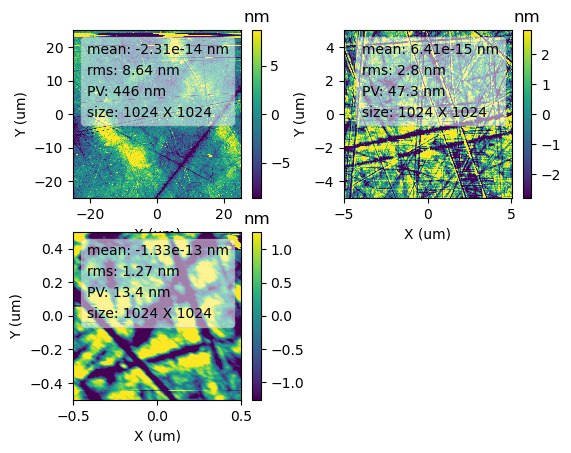

<Figure size 640x480 with 0 Axes>

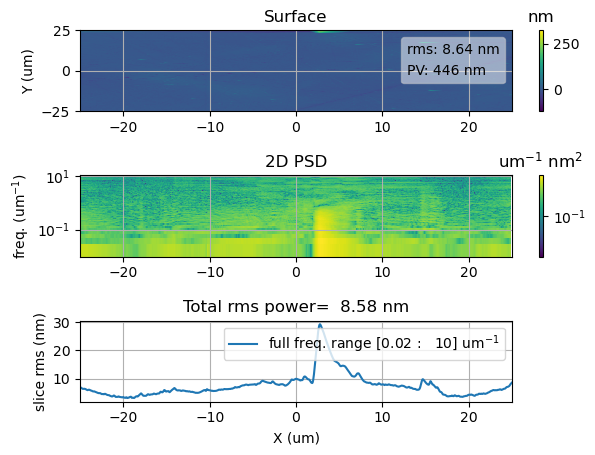

<Figure size 640x480 with 0 Axes>

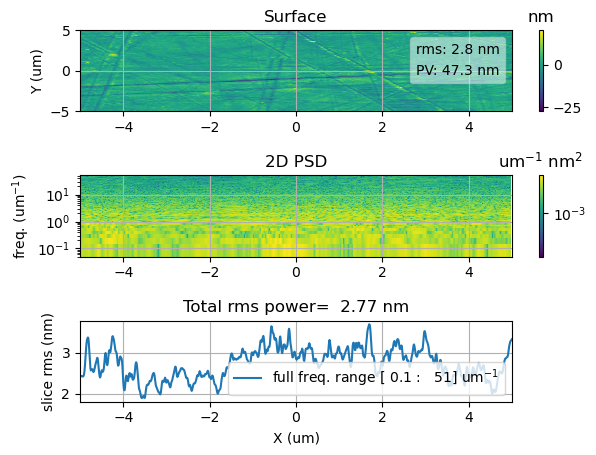

<Figure size 640x480 with 0 Axes>

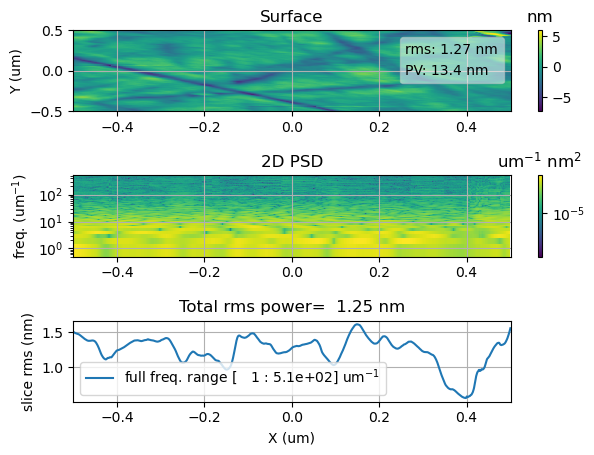

<Figure size 640x480 with 0 Axes>

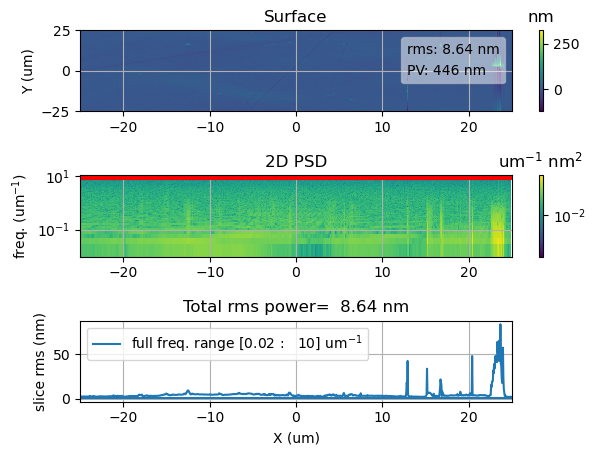

<Figure size 640x480 with 0 Axes>

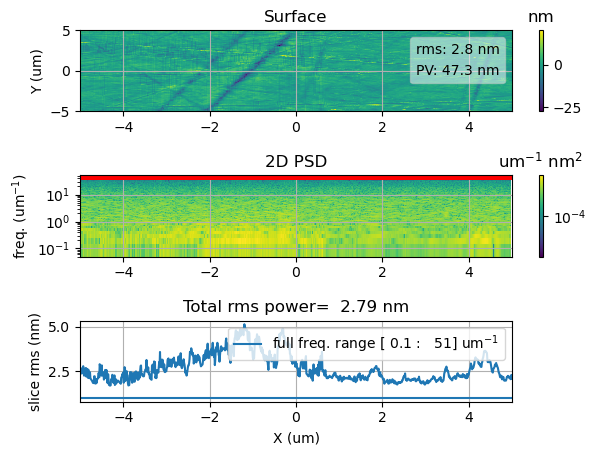

<Figure size 640x480 with 0 Axes>

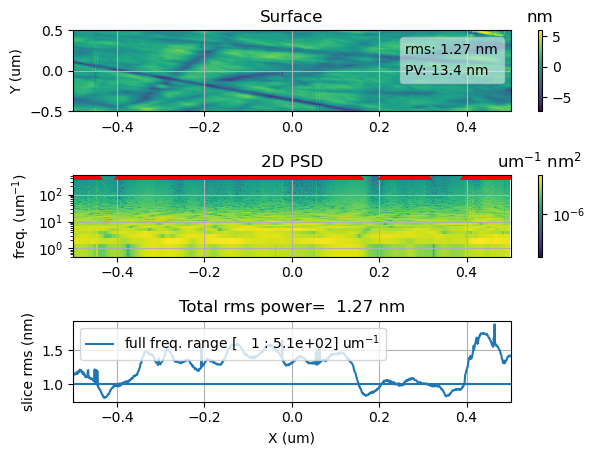

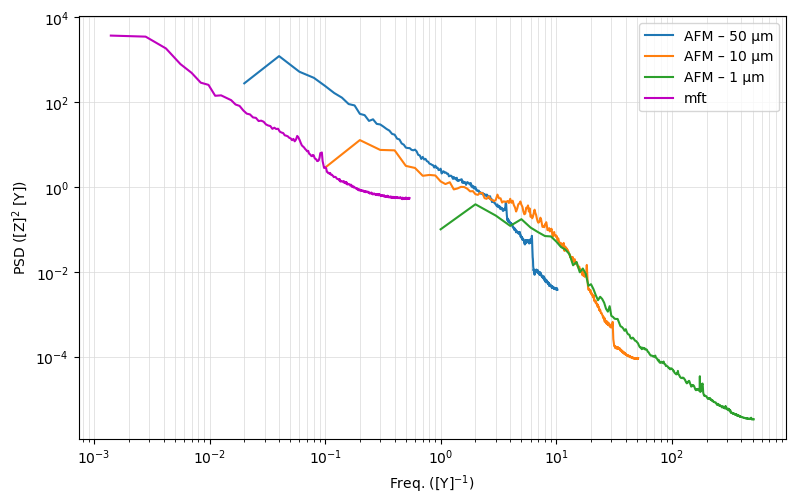

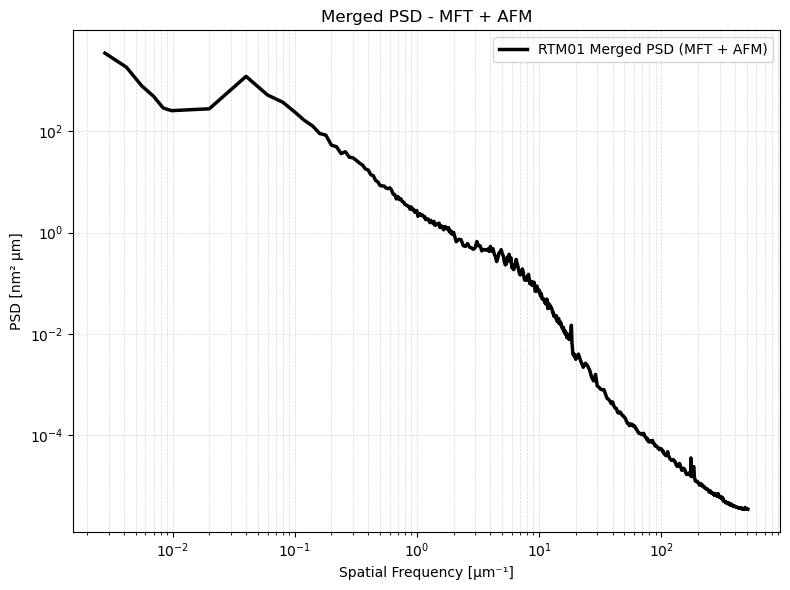

In [ ]:
#RTM01 AFM+MFT

#######################################################
#######################################################

#loading data
datafolder = r'/home/varun/PSD_AFM/RTM01_afm/' 
df = ['Image01953.nid',
      'Image01956.nid',
      'Image01962.nid']
files = [os.path.join(datafolder, f) for f in df]

#files = [os.path.join(datafolder, f) for f in df]
#outdir = r'results'  #os.path.join(datafolder,'results')
#outfolder = outdir 

labels = ['AFM - 1 um', 'AFM - 10 um', 'AFM - 50 um']

#psds = dopsd(files, labels, outfolder)
from pySurf.readers import nid_reader
data  = [read_nid(f) for f in files]
#dl = Dlist(data,units=['um','um','nm'],scale=[1e6,1e6,1e9],center = (0,0))
datalist = Dlist([Data2D(*d,units=['um','um','nm'],scale=[1e6,1e6,1e9],center = (0,0)) for d in data])  #TODO: allow reader

datalist = datalist.level(2,axis=1)
datalist.plot(type = 'grid')  #TOOD: allow figure output 
plt.show()  
afm_datalist = [(d, d.psd(analysis=True).avgpsd()) for d in datalist]


#################################################
#################################################

#plots of afm data

import os, pathlib, numpy as np, matplotlib.pyplot as plt
from pySurf.MIRO_analysis_functions import plot_psd

def psd_to_xy(psd): 
    for fx, fy in [('f','P'), ('x','y'), ('fx','py'), ('fx','P')]:
        if hasattr(psd, fx) and hasattr(psd, fy):
            return getattr(psd, fx), getattr(psd, fy)
    arr = psd.data if hasattr(psd, 'data') else psd
    return (arr[0], arr[1]) if arr.shape[0]==2 else (arr[:,0], arr[:,1])                            

#psd_list = [d.psd(axis=1, analysis=True, rmsthr=1).avgpsd()
#            for d in datalist]

#colors = ['tab:blue', 'tab:orange', 'tab:green']   # 1 µm, 10 µm, 50 µm
#labels = ['AFM – 50 µm', 'AFM – 10 µm', 'AFM – 1 µm']

#plt.figure(figsize=(8,5))
#for psd, c, lab in zip(psd_list, colors, labels):
#    f, P = psd_to_xy(psd)
    #print(f); print(P)
#    plot_psd(f, P, label=lab, color=c)           

#plt.xlabel('Frequenza spaziale [µm⁻¹]')
#plt.ylabel('PSD [nm² µm]')
#plt.grid(True, which='both', color='0.85', lw=0.5)
#plt.legend(loc='upper right')
#plt.tight_layout()                                                

#outdir = pathlib.Path().absolute() / 'AFM_results'
#outdir.mkdir(exist_ok=True)
#png_out = outdir / 'AFM_filtered_all.png'
#plt.savefig(png_out, dpi=300)
#plt.show()

#print('Grafico salvato in:', png_out)


##########################################
psd_list = [d.psd(axis=1, analysis=True, rmsthr=1).avgpsd()
            for d in datalist]

colors = ['tab:blue', 'tab:orange', 'tab:green']   # 1 µm, 10 µm, 50 µm
labels = ['AFM – 50 µm', 'AFM – 10 µm', 'AFM – 1 µm']

plt.figure(figsize=(8,5))
for psd, c, lab in zip(psd_list, colors, labels):
    f, P = psd_to_xy(psd)
    #print(f); print(P)
    plot_psd(f, P, label=lab, color=c)           

plt.xlabel('Frequenza spaziale [µm⁻¹]')
plt.ylabel('PSD [nm² µm]')
plt.grid(True, which='both', color='0.85', lw=0.5)
plt.legend(loc='upper right')
plt.tight_layout()                                                

#outdir = pathlib.Path().absolute() / 'AFM_results'
##outdir.mkdir(exist_ok=True)
#png_out = outdir / 'AFM_filtered_all.png'
#plt.savefig(png_out, dpi=300)
#plt.show()

#print('Grafico salvato in:', png_out)



datafolder = r'/home/varun/PSD_AFM/RTM01_afm'
filelist=['RTM01_m1.dat','RTM01_m2.dat','RTM01_m3.dat']
dataavgrtm01=[]
for fname in filelist:
    fn = os.path.join(datafolder, fname)
    data, x, y = matrixdat_reader(fn, center=(0, 0), scale=[1000., 1000., 1e9])
    d = Data2D(data, x, y, units=['mm', 'mm', 'nm'], name=os.path.basename(fn))

    # Detrending of order 4
    d4 = d.level(4)
    p2d=d.psd()
    # PSD calculation
    psd_avg = d4.psd().avgpsd()

    # PSD plot
    #psd_avg.plot(label=fname)
    dataavgrtm01.append(psd_avg)
#print(dataavg006)
#(np.average(dataavg008)).plot(label='008avg', marker='x',units=p2d.units)
psd_avg=np.average(dataavgrtm01)
#mft_flist=['m1.dat','m2.dat','m3.dat']
#mft_avglist=[]
#for file_singolo in mft_flist:
#    file_singolo = 'm2.dat'
#    fn = os.path.join(datafolder, file_singolo)

#    data, x, y = matrixdat_reader(fn, center=(0, 0), scale=[1000., 1000., 1e9])
#    d = Data2D(data, x, y, units=['mm', 'mm', 'nm'], name=os.path.basename(fn))

#    d4 = d.level(4)#, axis=0)  
#    psd_avg = d4.psd().avgpsd()
    #psd_avg.plot(); plt.show()
#    mft_avglist.append(psd_avg)
#psd_avg1=np.average(mft_avglist[0])

#file_singolo = 'm2.dat'
#fn = os.path.join(datafolder, file_singolo)

#data, x, y = matrixdat_reader(fn, center=(0, 0), scale=[1000., 1000., 1e9])
#d = Data2D(data, x, y, units=['mm', 'mm', 'nm'], name=os.path.basename(fn))

#d4 = d.level(4)#, axis=0)  
#psd_avg = d4.psd().avgpsd()
#psd_avg.plot(); plt.show()

f_single, P_single = psd_to_xy(psd_avg)

# Conversione da [1/mm] a [1/µm] e da [nm²*mm] a [nm²*µm]datafolder = r'/home/varun/PSD_AFM/'
f_single_um = f_single / 1000
P_single_um = P_single * 1000 


plot_psd(f_single_um, P_single_um, label='mft', color='m')
plt.show()


#################################################
#################################################

#merged full,single psd

f_1um, P_1um = psd_to_xy(psd_list[2])
f_10um, P_10um = psd_to_xy(psd_list[1])
f_50um, P_50um = psd_to_xy(psd_list[0])
#####################

fmin_mft = 0.01
fmin_10um = 2.0
fmin_1um = 20.0
min=0.002

# Seleziona i pezzi giusti
#mask_mft = (f_single_um <= fmin_mft) & (f_single_um>=min)
#mask_50um = (f_50um >= fmin_mft)&(f_50um <= fmin_10um) #aggiungo quei meno per collegarli meglio se no rimane uno spazietto
#mask_10um = (f_10um >= fmin_10um)&(f_10um <=fmin_1um )
#mask_1um = f_1um >= fmin_1um 

mask_mft = (f_single_um < fmin_mft) & (f_single_um>=min)
mask_50um = (f_50um >= fmin_mft)&(f_50um < fmin_10um) #aggiungo quei meno per collegarli meglio se no rimane uno spazietto
mask_10um = (f_10um >= fmin_10um)&(f_10um <fmin_1um )
mask_1um = f_1um >= fmin_1um 


f_merge_mft = f_single_um[mask_mft]
P_merge_mft = P_single_um[mask_mft]

f_merge_50um = f_50um[mask_50um]
P_merge_50um = P_50um[mask_50um]

f_merge_10um = f_10um[mask_10um]
P_merge_10um = P_10um[mask_10um]

f_merge_1um = f_1um[mask_1um]
P_merge_1um = P_1um[mask_1um]
###############################
###############################
# Merge completo

f_merged = np.concatenate([f_merge_mft, f_merge_50um, f_merge_10um, f_merge_1um])
P_merged = np.concatenate([P_merge_mft, P_merge_50um, P_merge_10um, P_merge_1um])

# Ordinamento corretto
order = np.argsort(f_merged)
f_mergedrtm01 = f_merged[order]
P_mergedrtm01 = P_merged[order]

#grafico
plt.figure(figsize=(8,6))

plt.loglog(f_mergedrtm01, P_mergedrtm01, color='k', lw=2.5, label='RTM01 Merged PSD (MFT + AFM)')
plt.xlabel('Spatial Frequency [µm⁻¹]')
plt.ylabel('PSD [nm² µm]')
plt.grid(True, which='both', linestyle='--', color='0.85', lw=0.5)
plt.legend()
plt.title('Merged PSD - MFT + AFM')
plt.tight_layout()
plt.show()


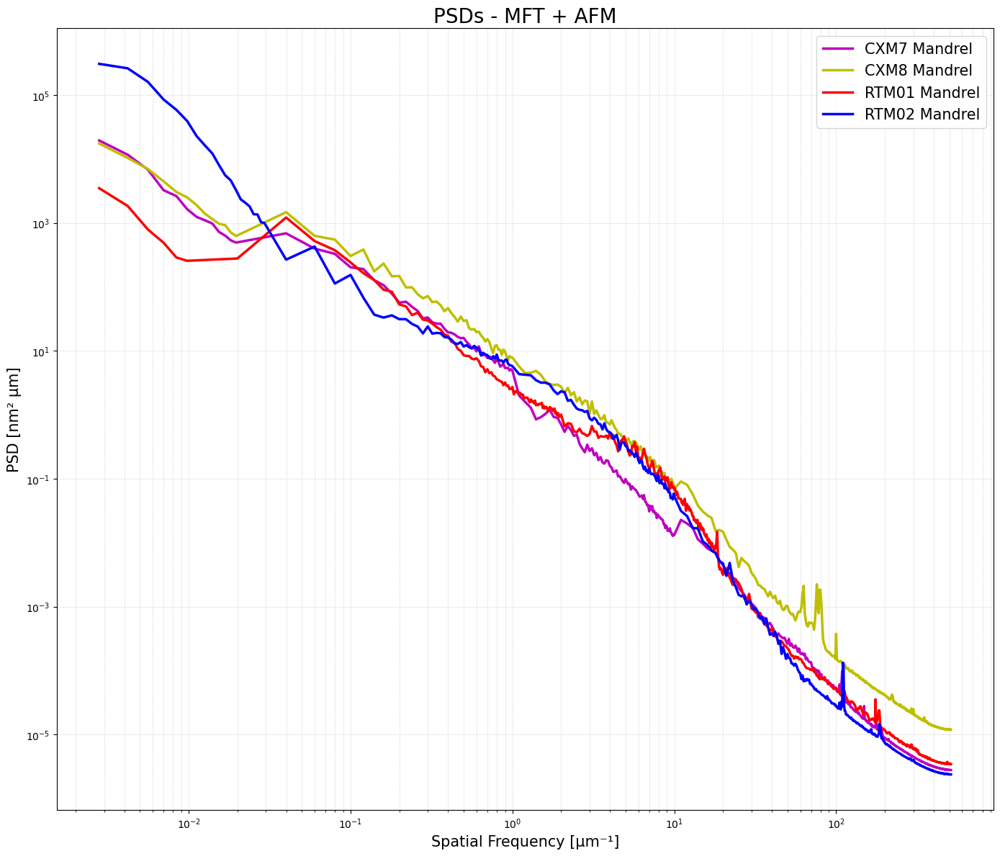

In [ ]:

#grafico
plt.figure(figsize=(14,12))

plt.loglog(f_mergedlmss01, P_mergedlmss01, color='m', lw=2.5, label='CXM7 Mandrel')

plt.loglog(f_mergedinox, P_mergedinox, color='y', lw=2.5, label='CXM8 Mandrel')

plt.loglog(f_mergedrtm01, P_mergedrtm01, color='r', lw=2.5, label='RTM01 Mandrel')

plt.loglog(f_mergedrtm02, P_mergedrtm02, color='b', lw=2.5, label='RTM02 Mandrel')

#plt.loglog(f_single_croc_um_vp, P_single_croc_um_vp, ls='--', lw=1.2, color='k')
#plt.loglog(f_mergedVP, P_mergedVP, color='k', ls='--', lw=2.5, label='Unslumped Glass')

#plt.loglog(f_single_croc_um_007, P_single_croc_um_007, ls='--', lw=1.2, color='b',alpha=0.4)
#plt.loglog(f_merged007, P_merged007, color='b', lw=2.5, label='Slumped Glass 007')



#plt.ylim(1e-6,5e8)
plt.xlabel('Spatial Frequency [µm⁻¹]',fontsize=15)
plt.ylabel('PSD [nm² µm]',fontsize=15)
plt.grid(True, which='both', linestyle='--', color='0.85', lw=0.5)
plt.legend(fontsize=15)
plt.title('PSDs - MFT + AFM',fontsize=20)
plt.tight_layout()
#plt.vlines(0.005,1e-10 , 1e8,ls='--',color='k')
#plt.vlines(1.0,1e-10 , 5e8,ls='--',color='k')
plt.show()


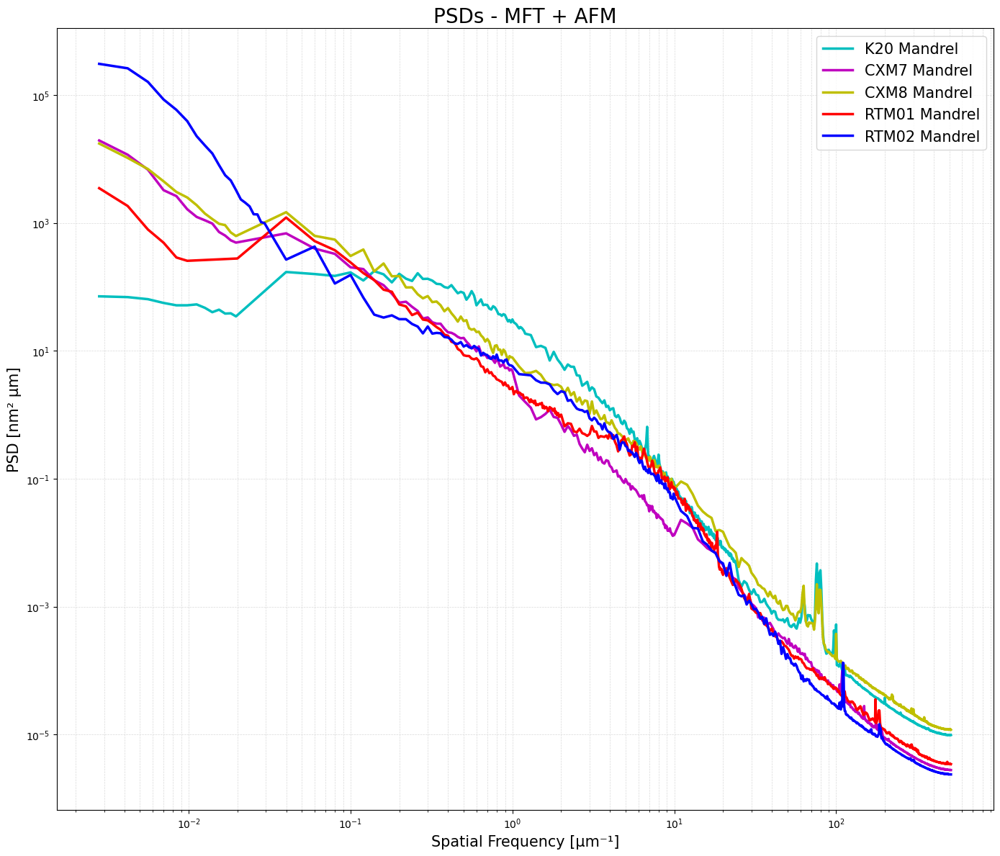

In [ ]:

#grafico
plt.figure(figsize=(14,12))

plt.loglog(f_mergedk20, P_mergedk20, color='c', lw=2.5, label='K20 Mandrel')

plt.loglog(f_mergedlmss01, P_mergedlmss01, color='m', lw=2.5, label='CXM7 Mandrel')

plt.loglog(f_mergedinox, P_mergedinox, color='y', lw=2.5, label='CXM8 Mandrel')

plt.loglog(f_mergedrtm01, P_mergedrtm01, color='r', lw=2.5, label='RTM01 Mandrel')

plt.loglog(f_mergedrtm02, P_mergedrtm02, color='b', lw=2.5, label='RTM02 Mandrel')

#plt.loglog(f_single_croc_um_vp, P_single_croc_um_vp, ls='--', lw=1.2, color='k')
#plt.loglog(f_mergedVP, P_mergedVP, color='k', ls='--', lw=2.5, label='Unslumped Glass')

#plt.loglog(f_single_croc_um_007, P_single_croc_um_007, ls='--', lw=1.2, color='b',alpha=0.4)
#plt.loglog(f_merged007, P_merged007, color='b', lw=2.5, label='Slumped Glass 007')



#plt.ylim(1e-6,5e8)
plt.xlabel('Spatial Frequency [µm⁻¹]',fontsize=15)
plt.ylabel('PSD [nm² µm]',fontsize=15)
plt.grid(True, which='both', linestyle='--', color='0.85', lw=0.5)
plt.legend(fontsize=15)
plt.title('PSDs - MFT + AFM',fontsize=20)
plt.tight_layout()
#plt.vlines(0.005,1e-10 , 1e8,ls='--',color='k')
#plt.vlines(1.0,1e-10 , 5e8,ls='--',color='k')
plt.show()


In [ ]:
import pandas as pd 

psd_dat_k20=pd.DataFrame({'f_k20': np.asarray(f_mergedk20), 'p_k20': np.asarray(P_mergedk20)})
psd_dat_lmss01=pd.DataFrame({'f_lmss01': np.asarray(f_mergedlmss01), 'p_lmss01': np.asarray(P_mergedlmss01)})
psd_dat_lmss02=pd.DataFrame({'f_lmss02': np.asarray(f_mergedinox), 'p_lmss02': np.asarray(P_mergedinox)})
psd_dat_rtm01=pd.DataFrame({'f_rtm01': np.asarray(f_mergedrtm01), 'p_rtm01': np.asarray(P_mergedrtm01)})
psd_dat_rtm02=pd.DataFrame({'f_rtm02': np.asarray(f_mergedrtm02), 'p_rtm02': np.asarray(P_mergedrtm02)})


datf=pd.concat([psd_dat_k20,psd_dat_lmss01,psd_dat_lmss02,psd_dat_rtm01,psd_dat_rtm02], axis=1)


In [ ]:
datf.to_csv('mandrel_psd_data.txt', sep='\t', index=False)

In [9]:
pwd

'g:\\Shared drives\\SlumpingOAB\\metrology_data\\analysis\\20250909_RP2'

In [9]:
fpsd = r'mandrel_psd_data.txt'

# np.genfromtxt(fpsd, skip_header=1, unpack=True)

In [10]:
import pandas as pd
a = pd.read_csv(fpsd, sep='\t')
a

,f_k20,p_k20,f_lmss01,p_lmss01,f_lmss02,p_lmss02,f_rtm01,p_rtm01,f_rtm02,p_rtm02
0,0.002797,70.942123,0.002797,19412.531380,0.002797,17380.557551,0.002797,3482.224179,0.002797,306383.158971
1,0.004196,68.984622,0.004196,11616.929008,0.004196,10355.838134,0.004196,1834.758572,0.004196,260991.410394
2,0.005595,64.022719,0.005595,6788.265392,0.005595,6943.387055,0.005595,787.116356,0.005595,160055.905691
3,0.006993,55.919068,0.006993,3241.165098,0.006993,4457.649941,0.006993,488.934307,0.006993,84854.322880
4,0.008392,51.325792,0.008392,2619.207258,0.008392,3040.203735,0.008392,287.289780,0.008392,58453.960469
...,...,...,...,...,...,...,...,...,...,...
783,507.503906,0.000010,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
784,508.502930,0.000010,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
785,509.501953,0.000010,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
786,510.500977,0.000010,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


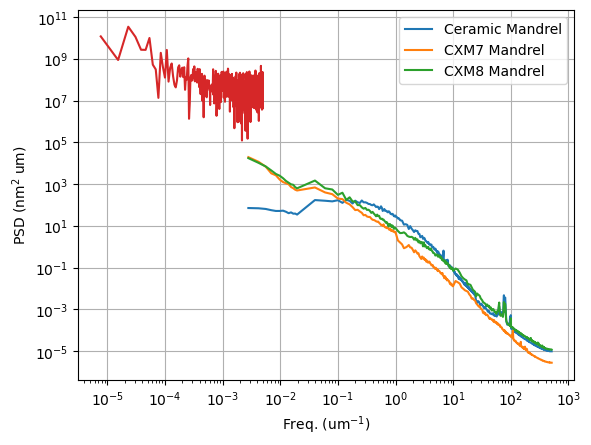

In [25]:


# tag = 'lmss01'
from pyProfile.profile_class import Profile, Plist, PSD

datadic = {'k20': 'Ceramic Mandrel',
           'lmss01': 'CXM7 Mandrel',
           'lmss02': 'CXM8 Mandrel'}

psds = []
for tag in datadic.keys():
    ff,pp = a['f_%s'%tag].to_numpy(),a['p_%s'%tag].to_numpy()
    p = PSD (ff,pp,units=['$\mu$m','nm'],name=datadic[tag])
    psds.append(p)

psds = Plist(psds)
# plot_psd(f1,p1)
psds.plot(mode='all')
p1.level(2).psd().plot()

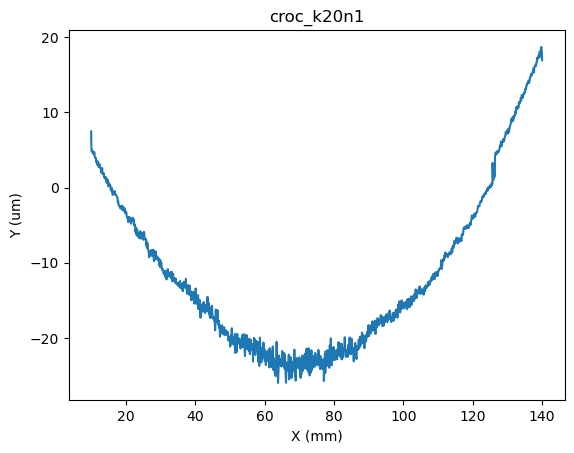

In [8]:
p1.plot()

In [ ]:
#Graphic 

plt.figure(figsize=(14,12))

#plt.loglog(f_mergedWafer, P_mergedWafer, color='y', ls='--', lw=2.5, label='Silicon Wafer')

plt.loglog(f_single_croc_um_k20, P_single_croc_um_k20, ls='--', lw=1.2,color='r',alpha=0.6)
plt.loglog(f_mergedk20, P_mergedk20, color='r', lw=2.5, label='Ceramic Mandrel')

plt.loglog(f_single_croc_um_inox, P_single_croc_um_inox, ls='--', lw=1.2,color='y',alpha=0.6)
plt.loglog(f_mergedinox, P_mergedinox, color='y', lw=2.5, label='CXM8 Mandrel')


plt.loglog(f_single_croc_um_lmss01, P_single_croc_um_lmss01, ls='--', lw=1.2,color='g',alpha=0.6)
plt.loglog(f_mergedlmss01, P_mergedlmss01, color='g', lw=2.5, label='CXM7 Mandrel')



plt.ylim(1e-6,5e8)
plt.xlabel('Spatial Frequency [µm⁻¹]',fontsize=15)
plt.ylabel('PSD [nm² µm]',fontsize=15)
plt.grid(True, which='both', linestyle='--', color='0.85', lw=0.5)
plt.legend(fontsize=15)
plt.title('PSDs - Profilometer + MFT + AFM',fontsize=20)
plt.tight_layout()
#plt.vlines(0.005,1e-10 , 1e8,ls='--',color='k')
#plt.vlines(1.0,1e-10 , 5e8,ls='--',color='k')
plt.show()

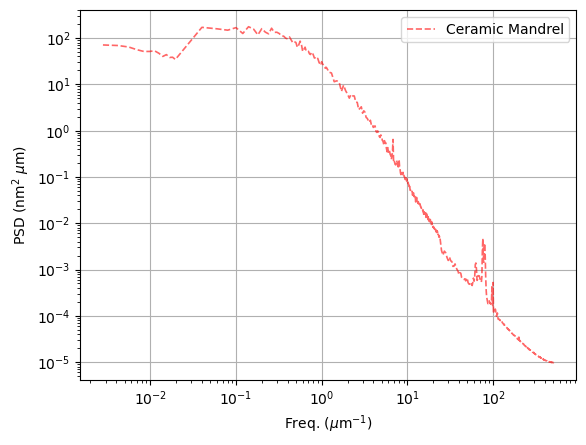

In [35]:
psds[0].plot(ls='--', lw=1.2,color='r',alpha=0.6)

In [ ]:
import matplotlib.pyplot as plt
fig,ax=plt.subplots(figsize=(16,12))
#plt.figure(figsize=(16,12))
#Profilometer curves
#plt.loglog(label='Wafer',color='k',ls='--')
plt.loglog(profvp_fin.x/1000,profvp_fin.y*1000,color='y',ls='--',alpha=0.5,linewidth=2)
plt.loglog(prof008_fin.x/1000,prof008_fin.y*1e6,color='b',ls='--',alpha=0.5,linewidth=2)
plt.loglog(profss02_fin.x,profss02_fin.y,color='r',ls='--',alpha=0.5,linewidth=2)
plt.loglog(prof008_fin.x,prof008_fin.y/1e3,color='b',ls='--',alpha=0.5,linewidth=2)

#AFM+MFT curves

plt.loglog(F_merged_wafer,P_merged_wafer,color='k',ls='--',label='Silicon Wafer',linewidth=3)
plt.loglog(F_merged_vp,P_merged_vp,label='Unslumped Glass',color='y',linewidth=3)
plt.loglog(F_merged_008,P_merged_008,label='Slumped Glass 008',color='b',linewidth=3)
plt.loglog(F_merged_ss02,P_merged_ss02,label='Stainless Steel Mandrel',color='r',linewidth=3)
#plt.xlabel=('Frequency (1/um)')
ax.set_xlabel('Spatial Frequency [μm$^{−1}$]',fontsize=25)
#plt.ylabel=('PSD')
ax.set_ylabel('PSD [nm$^{2}$ μm]',fontsize=25)
ax.set_title('PSDs - Profilometer + AFM + MFT',fontsize=25)
#ax.set_title=('Merged PSD')
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
plt.legend(fontsize=20)
plt.grid()
plt.vlines(1e0,1e-9,1e11,color='k',ls='--',linewidth=2.5)
plt.ylim(1e-9,1e11)
#plt.xlim(1e-5,None)
plt.xlim(3e-6,None)
plt.show()